In [ ]:
import ast

file_path = 'D:\\Licenta\\meta_Electronics.json\\meta_Electronics.json'
output_file = 'ierarhie_categorii.txt'

class TreeNode:
    def __init__(self, name):
        self.name = name
        self.count = 0
        self.children = {}

root = TreeNode("ROOT")

linii_procesate = 0

with open(file_path, 'r', encoding='utf-8') as f:
    for line in f:
        linii_procesate += 1
        if linii_procesate % 50000 == 0:
            print(f"  -> {linii_procesate} linii procesate...")

        try:
            try:
                item = ast.literal_eval(line.strip())
            except:
                item = eval(line.strip())

            categories = item.get('categories', [])
            if not categories:
                continue

            added_paths = set()

            for path in categories:
                current_node = root

                full_path_id = ""

                for cat in path:
                    full_path_id += cat + "|"

                    if cat not in current_node.children:
                        current_node.children[cat] = TreeNode(cat)

                    current_node = current_node.children[cat]

                    if full_path_id not in added_paths:
                        current_node.count += 1
                        added_paths.add(full_path_id)

        except Exception:
            continue


def write_tree(node, file_obj, prefix="", is_last=True, depth=0, max_depth=None):
    if max_depth is not None and depth > max_depth:
        return

    if node.name != "ROOT":
        connector = "└── " if is_last else "├── "
        linie = f"{prefix}{connector}{node.name} ({node.count})"
        file_obj.write(linie + "\n")

        if depth <= 2:
            print(linie)

        if is_last:
            prefix += "    "
        else:
            prefix += "│   "

    children = sorted(node.children.values(), key=lambda x: x.count, reverse=True)
    for i, child in enumerate(children):
        write_tree(
            node=child,
            file_obj=file_obj,
            prefix=prefix,
            is_last=(i == len(children) - 1),
            depth=depth + 1,
            max_depth=max_depth
        )

with open(output_file, 'w', encoding='utf-8') as out_f:
    write_tree(root, out_f, max_depth=None)


  -> 50000 linii procesate...
  -> 100000 linii procesate...
  -> 150000 linii procesate...
  -> 200000 linii procesate...
  -> 250000 linii procesate...
  -> 300000 linii procesate...
  -> 350000 linii procesate...
  -> 400000 linii procesate...
  -> 450000 linii procesate...
├── Electronics (498196)
│   ├── Computers & Accessories (233684)
│   ├── Camera & Photo (94857)
│   ├── Accessories & Supplies (68026)
│   ├── Portable Audio & Video (35368)
│   ├── Car & Vehicle Electronics (25993)
│   ├── Television & Video (11437)
│   ├── Home Audio (9806)
│   ├── eBook Readers & Accessories (7489)
│   ├── GPS & Navigation (7078)
│   ├── Security & Surveillance (4330)
│   ├── Electronics Warranties (1239)
│   ├── Service & Replacement Plans (91)
│   └── Cell Phones & Accessories (4)
├── Cell Phones & Accessories (2684)
│   ├── Cases (1422)
│   ├── Accessories (1252)
│   ├── Cell Phones (21)
│   └── Connected Devices (12)
├── Kindle Store (597)
│   ├── Kindle Accessories (594)
│   └── Kindle e

In [ ]:
file_path = 'D:\\Licenta\\meta_Electronics.json\\meta_Electronics.json'

import ast
import random
import numpy as np
import torch

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

TARGET_CLASSES = [
    'Film Photography', 'Digital Cameras', 'Binoculars & Scopes',
    'Lenses', 'Tripods & Monopods', 'Video Surveillance',
    'Lighting & Studio', 'Flashes',   'Video Cables', 'Audio Cables', 'TV Accessories & Parts',
    'Headphone Accessories', 'Connectors & Adapters', 'Media Storage & Organization',
    'Distribution', 'Telephone Accessories'
]

def extract_target_class(categories):
    if not categories:
        return None
    for path in categories:
        for cat in path:
            if cat in TARGET_CLASSES:
                return cat
    return None

products = {}
edges = []

stats = {
    'total_lines': 0,
    'successfully_parsed': 0,
    'syntax_errors_eval': 0,
    'missing_class_in_categories': 0
}

with open(file_path, 'r', encoding='utf-8') as f:
    for line in f:
        stats['total_lines'] += 1

        try:
            try:
                import ast
                item = ast.literal_eval(line.strip())
            except:
                item = eval(line.strip())

            asin = item.get('asin')
            categories = item.get('categories', [])

            target_class = extract_target_class(categories)
            if target_class:
                title = item.get('title', '')
                description = item.get('description', '')
                text_content = f"{title} {description}"

                products[asin] = {
                    'class': target_class,
                    'text': text_content,
                    'related': item.get('related', {})
                }
                stats['successfully_parsed'] += 1
            else:
                stats['missing_class_in_categories'] += 1

        except Exception as e:
            stats['syntax_errors_eval'] += 1
            if stats['syntax_errors_eval'] <= 3:
                print(f"\nError: {e}")
                print(f"Line: {line[:150]}...")

for k, v in stats.items():
    print(f"{k}: {v}")



linii_totale: 498196
linii_cu_target_string: 0
parsate_cu_succes: 65679
erori_sintaxa_eval: 0
lipsa_clasa_in_categorii: 432517

Am extras 65679 produse valide în dicționar.


In [ ]:
import numpy as np
import scipy.sparse as sp


def eliminate_self_loops(A):
    """Remove self-loops from the adjacency matrix."""
    A = A.tolil()
    A.setdiag(0)
    A = A.tocsr()
    A.eliminate_zeros()
    return A


def largest_connected_components(sparse_graph, n_components=1):
    """Select the largest connected components in the graph."""
    _, component_indices = sp.csgraph.connected_components(sparse_graph.adj_matrix)
    component_sizes = np.bincount(component_indices)
    components_to_keep = np.argsort(component_sizes)[::-1][:n_components] 
    nodes_to_keep = [
        idx for (idx, component) in enumerate(component_indices) if component in components_to_keep
    ]
    return create_subgraph(sparse_graph, nodes_to_keep=nodes_to_keep)


def create_subgraph(sparse_graph, nodes_to_keep=None):
    """Create a graph with the specified subset of nodes."""

    nodes_to_keep = sorted(nodes_to_keep)

    sparse_graph.adj_matrix = sparse_graph.adj_matrix[nodes_to_keep][:, nodes_to_keep]
    sparse_graph.attr_matrix = sparse_graph.attr_matrix[nodes_to_keep]
    sparse_graph.labels = sparse_graph.labels[nodes_to_keep]
    sparse_graph.node_names = sparse_graph.node_names[nodes_to_keep]
    return sparse_graph



In [ ]:
import numpy as np
import scipy.sparse as sp


class SparseGraph:
    """Attributed labeled graph stored in sparse matrix form.

    """
    def __init__(self, adj_matrix, attr_matrix=None, labels=None,
                 node_names=None, attr_names=None, class_names=None, metadata=None):
        """Create an attributed graph."""
        if sp.isspmatrix(adj_matrix):
            adj_matrix = adj_matrix.tocsr().astype(np.float32)

        if attr_matrix is not None:
            if sp.isspmatrix(attr_matrix):
                attr_matrix = attr_matrix.tocsr().astype(np.float32)
            elif isinstance(attr_matrix, np.ndarray):
                attr_matrix = attr_matrix.astype(np.float32)
          
        self.adj_matrix = adj_matrix
        self.attr_matrix = attr_matrix
        self.labels = labels
        self.node_names = node_names
        self.attr_names = attr_names
        self.class_names = class_names
        self.metadata = metadata

    def num_nodes(self):
        return self.adj_matrix.shape[0]

    def num_edges(self):
        """Get the number of edges in the graph."""
        if self.is_directed():
            return int(self.adj_matrix.nnz)
        else:
            return int(self.adj_matrix.nnz / 2)

    def get_neighbors(self, idx):
        """Get the indices of neighbors of a given node."""
        return self.adj_matrix[idx].indices

    def is_directed(self):
        """Check if the graph is directed."""
        return (self.adj_matrix != self.adj_matrix.T).sum() != 0

    def to_undirected(self):
        """Convert to an undirected graph."""
        self.adj_matrix = self.adj_matrix + self.adj_matrix.T
        self.adj_matrix[self.adj_matrix != 0] = 1
        return self

    def is_weighted(self):
        """Check if the graph is weighted."""
        return np.any(np.unique(self.adj_matrix[self.adj_matrix != 0].A1) != 1)

    def to_unweighted(self):
        """Convert to an unweighted graph."""
        self.adj_matrix.data = np.ones_like(self.adj_matrix.data)
        return self

    def standardize(self):
        """Select the LCC of the unweighted/undirected/no-self-loop graph."""
        G = self.to_unweighted().to_undirected()
        G = eliminate_self_loops_adj(G)
        n_components, _ = sp.csgraph.connected_components(G.adj_matrix)
        print(n_components)
        G = largest_connected_components(G, 10)
        return G


def eliminate_self_loops_adj(G):
    G.adj_matrix = eliminate_self_loops(G.adj_matrix)
    return G


def save_sparse_graph_to_npz(filepath, sparse_graph):
    """Save a SparseGraph to a Numpy binary file."""
    data_dict = {
        'adj_data': sparse_graph.adj_matrix.data,
        'adj_indices': sparse_graph.adj_matrix.indices,
        'adj_indptr': sparse_graph.adj_matrix.indptr,
        'adj_shape': sparse_graph.adj_matrix.shape
    }
   
    data_dict['attr_data'] = sparse_graph.attr_matrix.data
    data_dict['attr_indices'] = sparse_graph.attr_matrix.indices
    data_dict['attr_indptr'] = sparse_graph.attr_matrix.indptr
    data_dict['attr_shape'] = sparse_graph.attr_matrix.shape

    data_dict['labels'] = sparse_graph.labels    
    data_dict['node_names'] = sparse_graph.node_names
    data_dict['class_names'] = sparse_graph.class_names

    if not filepath.endswith('.npz'):
        filepath += '.npz'

    np.savez(filepath, **data_dict)


In [ ]:
import numpy as np
import scipy.sparse as sp
import re

asin_list = list(products.keys())
asin_to_idx = {asin: idx for idx, asin in enumerate(asin_list)}
num_nodes_raw = len(asin_to_idx)
print(f"Products: {num_nodes_raw}")

class_to_idx = {name: i for i, name in enumerate(TARGET_CLASSES)}
labels_raw = np.zeros(num_nodes_raw, dtype=np.int64)
texts_raw  = [""] * num_nodes_raw

for asin, data in products.items():
    idx = asin_to_idx[asin]
    labels_raw[idx] = class_to_idx[data['class']]
    texts_raw[idx]  = data['text']

# Build adjacency matrix
edge_list = []
for asin, data in products.items():
    src_idx = asin_to_idx[asin]
    for target_asin in data.get('related', {}).get('also_bought', []):
        if target_asin in asin_to_idx:
            edge_list.append((src_idx, asin_to_idx[target_asin]))

if edge_list:
    edges_arr    = np.array(edge_list)
    adj_matrix_raw = sp.csr_matrix(
        (np.ones(len(edges_arr)), (edges_arr[:, 0], edges_arr[:, 1])),
        shape=(num_nodes_raw, num_nodes_raw)
    )
    adj_matrix_raw = adj_matrix_raw + adj_matrix_raw.T
    adj_matrix_raw[adj_matrix_raw > 1.0] = 1.0
else:
    adj_matrix_raw = sp.csr_matrix((num_nodes_raw, num_nodes_raw))

placeholder_attr = sp.eye(num_nodes_raw, format='csr', dtype=np.float32)

graph_struct = SparseGraph(
    adj_matrix  = adj_matrix_raw,
    attr_matrix = placeholder_attr,
    labels      = labels_raw,
    node_names  = np.array(asin_list),
    class_names = np.array(TARGET_CLASSES)
)

valid_text_mask = np.array([1 if texts_raw[i].strip() else 0
                             for i in range(num_nodes_raw)])
valid_node_indices = np.where(valid_text_mask > 0)[0]
graph_struct = create_subgraph(graph_struct, nodes_to_keep=valid_node_indices)

graph_struct = graph_struct.standardize()

print(f"Nodes remaining after structural filtering: {graph_struct.num_nodes()}")
print(f"Edges remaining: {graph_struct.num_edges()}")

final_asins = graph_struct.node_names.tolist()
final_texts = [products[asin]['text'] for asin in final_asins]

# Clean HTML/XML/CSS noise from product text 
def clean_text(text):
    """Strip HTML tags, MS Word XML conditionals, CSS blocks, HTML entities."""
    # Remove MS Word conditional comments
    text = re.sub(r'\[if[^\]]*\].*?\[endif\]', ' ', text, flags=re.DOTALL)
    # Remove HTML/XML tags
    text = re.sub(r'<[^>]+>', ' ', text)
    # Remove HTML entities 
    text = re.sub(r'&[a-zA-Z0-9#]+;', ' ', text)
    # Remove CSS-like blocks 
    text = re.sub(r'\{[^}]+\}', ' ', text)
    # Collapse whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

final_texts = [clean_text(t) for t in final_texts]

from sentence_transformers import SentenceTransformer

sbert_model = SentenceTransformer('all-mpnet-base-v2')  # 768-dim
embeddings = sbert_model.encode(
    final_texts,
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True,
).astype(np.float32)

attr_matrix_final = sp.csr_matrix(embeddings) 
print(f"SBERT embeddings: {attr_matrix_final.shape}")  

# Assemble the final clean graph 
graph_final = SparseGraph(
    adj_matrix  = graph_struct.adj_matrix,
    attr_matrix = attr_matrix_final,
    labels      = graph_struct.labels,
    node_names  = graph_struct.node_names,
    class_names = np.array(TARGET_CLASSES)
)

save_sparse_graph_to_npz('my_amazon_photo_custom.npz', graph_final)
print("Graph saved.")

Produse brute: 65679
45793
Noduri rămase după filtrare structurală: 19438
Muchii rămase: 193951


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/304 [00:00<?, ?it/s]

SBERT embeddings: (19438, 768)
Graf salvat.


In [5]:
import torch

def check_torch_version():
    if torch.cuda.is_available():
        print(f"CUDA is available. Torch version: {torch.__version__}, CUDA version: {torch.version.cuda}")
    else:
        print(f"CUDA is not available. Torch version: {torch.__version__}")
check_torch_version()

CUDA is not available. Torch version: 2.11.0+cpu


In [6]:
import os

def install_torch_geometric():
    TORCH_VERSION = torch.__version__
    if TORCH_VERSION.startswith('2.1.0') and torch.cuda.is_available():
        # Specific installation for CUDA 12.1 if torch 2.1.0 is detected
        print("Detected torch 2.1.0 with CUDA, installing PyTorch Geometric for CUDA 12.1...")
        os.system('pip install torch_geometric')
    elif TORCH_VERSION.startswith('2.2.0') and torch.cuda.is_available():
        # Specific installation for CUDA 12.1 if torch 2.2.0 is detected
        print("Detected torch 2.2.0 with CUDA, installing PyTorch Geometric for CUDA 12.1...")
        os.system('pip install torch_geometric')
    else:
        print(f"Installing PyTorch Geometric for torch {TORCH_VERSION} (CPU or other CUDA versions). This might take a moment...")
        os.system('pip install torch_geometric')

install_torch_geometric()

Installing PyTorch Geometric for torch 2.11.0+cpu (CPU or other CUDA versions). This might take a moment...


In [ ]:
import os
import os.path as osp
import numpy as np
import scipy.sparse as sp
import random
import shutil

import torch
import torch.nn.functional as F
from torch_geometric.data import Data, InMemoryDataset
from torch_geometric.utils import remove_self_loops, to_undirected

import warnings
warnings.filterwarnings('ignore')


def read_amazon_data(folder, filename):
    file_path = osp.join(folder, filename)
    with np.load(file_path) as loader:
        loader = dict(loader)

        # 1. Load nodes (Features)
        x = sp.csr_matrix((loader['attr_data'], loader['attr_indices'],
                           loader['attr_indptr']), shape=loader['attr_shape'])
        x = torch.Tensor(x.todense()).to(torch.float)

        # 2. Load labels
        y = torch.Tensor(loader.get('labels')).long()

        # 3. Load edges
        adj = sp.csr_matrix((loader['adj_data'], loader['adj_indices'],
                             loader['adj_indptr']), shape=loader['adj_shape']).tocoo()
        edge_index = torch.tensor([adj.row, adj.col], dtype=torch.long)
        edge_index, _ = remove_self_loops(edge_index)
        edge_index = to_undirected(edge_index, x.size(0))

        # 4. Return the clean graph (without masks)
        data = Data(x=x, edge_index=edge_index, y=y)

        return data

class CustomAmazonPhoto(InMemoryDataset):
    def __init__(self, root, transform=None, pre_transform=None):
        self.custom_filename = 'my_amazon_photo_custom.npz'
        super(CustomAmazonPhoto, self).__init__(root, transform, pre_transform)
        self.data, self.slices = torch.load(self.processed_paths[0], weights_only=False)

    @property
    def raw_file_names(self):
        return [self.custom_filename]

    @property
    def processed_file_names(self):
        return 'custom_data.pt'

    def download(self):
        if osp.exists(self.custom_filename):
            os.makedirs(self.raw_dir, exist_ok=True)
            shutil.copy(self.custom_filename, osp.join(self.raw_dir, self.custom_filename))
        else:
            raise FileNotFoundError(f"File not found: {self.custom_filename}")

    def process(self):
        data = read_amazon_data(self.raw_dir, self.custom_filename)
        data = data if self.pre_transform is None else self.pre_transform(data)
        data, slices = self.collate([data])
        torch.save((data, slices), self.processed_paths[0])

In [ ]:
dataset = CustomAmazonPhoto(root='./data/AmazonPhoto')
data = dataset[0]
print(f'The dataset contains: {len(dataset)} graph(s)')
print(f'Number of nodes (photo products): {data.num_nodes}')
print(f'Number of edges ("bought together" links): {data.num_edges}')
print(f'Number of features (attributes per product): {data.num_node_features}')
print(f'Number of classes (product categories): {dataset.num_classes}')
print(f'Is the graph undirected? {data.is_undirected()}')
print(f'Are there isolated nodes? {data.has_isolated_nodes()}')


=== INFORMAȚII GENERALE DESPRE DATASET-UL AMAZON PHOTO ===
Seta de date conține: 1 graf(uri)
Număr de noduri (produse foto): 19438
Număr de muchii (legături "bought together"): 387902
Număr de feature-uri (atribute per produs): 768
Număr de clase (categorii de produse): 16
Graful este neorientat? True
Conține noduri izolate? False


In [ ]:
node_id = 0

print(f"EQUIVALENT OF A 'DATA ROW' (NODE {node_id}) \n")

label_id = data.y[node_id].item()
print(f"CLASS (Category): {label_id}")

node_features = data.x[node_id].numpy()
active_feature_indices = np.where(node_features > 0)[0]

print(f"ATTRIBUTES (Features):")
print(f"   - The product has a feature vector of {len(node_features)} dimensions (e.g., possible words in the description).")
print(f"   - Of these, only {len(active_feature_indices)} are active (have a value > 0).")
print(f"   - Indices of active features (e.g., word IDs in the dictionary):")
print(f"     {active_feature_indices}\n")

source_nodes = data.edge_index[0].numpy()
target_nodes = data.edge_index[1].numpy()

neighbors = target_nodes[source_nodes == node_id]

print(f"CONNECTIONS (Frequently bought together with):")
print(f"   - This product is connected to {len(neighbors)} other products.")
print(f"   - IDs of complementary products (neighbors in the graph) are:")
print(f"     {neighbors}")

========== ECHIVALENTUL UNEI 'LINII' DE DATE (NODUL 0) ==========

CLASA (Categoria): 10
ATRIBUTE (Features):
   - Produsul are un vector de 768 de dimensiuni (ex: cuvinte posibile în descriere).
   - Dintre acestea, doar 380 sunt active (au valoarea > 0).
   - Indicii atributelor active (ex: ID-urile cuvintelor din dicționar):
     [  0   2   4   5   6   7   8  10  12  13  14  17  18  21  22  25  28  31
  32  33  34  37  39  40  43  44  46  49  52  55  56  57  59  61  69  70
  71  72  75  77  81  86  87  92  93  96  98 101 103 105 109 111 117 119
 120 121 122 124 125 130 131 132 133 134 135 136 137 138 139 141 142 143
 144 145 147 150 152 153 154 155 159 160 161 162 163 167 171 175 179 182
 183 187 191 193 194 195 200 201 202 203 204 205 208 209 211 213 215 217
 222 224 226 227 229 230 231 233 234 236 237 240 242 243 244 245 248 250
 251 252 254 255 257 263 269 270 271 272 274 278 279 280 283 285 286 290
 292 295 296 297 298 299 300 303 307 308 310 314 316 319 320 321 324 325
 327 329

In [ ]:
import numpy as np
import scipy.sparse as sp

file_path = 'my_amazon_photo_custom.npz'

node_id = 0

with np.load(file_path) as loader:
    loader = dict(loader)
    print(loader)
    class_names = loader['class_names']
    labels = loader['labels']
    node_label_id = labels[node_id]
    node_class_name = class_names[node_label_id]
    attr_names = loader.get('attr_names')

    x = sp.csr_matrix((loader['attr_data'], loader['attr_indices'], loader['attr_indptr']), shape=loader['attr_shape'])
    node_features = x.getrow(node_id).toarray()[0]
    active_features = np.where(node_features > 0)[0]

    adj = sp.csr_matrix((loader['adj_data'], loader['adj_indices'], loader['adj_indptr']), shape=loader['adj_shape'])
    node_edges = adj.getrow(node_id).indices

    print("COMPLETE PROFILE OF A PRODUCT (NODE) ===\n")
    print("{")
    print(f"  \"product_graph_id\": {node_id},")
    print(f"  \"category_id\": {node_label_id},")
    print(f"  \"category_name\": \"{node_class_name}\",")
    print(f"  \"total_keywords_in_description\": {len(active_features)},")
    print(f"  \"active_keyword_ids\": {active_features.tolist()[:10]} ... (and more),")
    print(f"  \"total_frequently_bought_together\": {len(node_edges)},")
    print(f"  \"frequently_bought_together_ids\": {node_edges.tolist()}")
    print("}")

{'adj_data': array([1., 1., 1., ..., 1., 1., 1.], dtype=float32), 'adj_indices': array([  225,   500,  1907, ..., 14908, 18447, 19188], dtype=int32), 'adj_indptr': array([     0,    125,    132, ..., 387889, 387890, 387902], dtype=int32), 'adj_shape': array([19438, 19438]), 'attr_data': array([ 0.03151429, -0.06883536,  0.01089632, ..., -0.00420637,
       -0.0510882 , -0.09735975], dtype=float32), 'attr_indices': array([  0,   1,   2, ..., 765, 766, 767], dtype=int32), 'attr_indptr': array([       0,      768,     1536, ..., 14926848, 14927616, 14928384],
      dtype=int32), 'attr_shape': array([19438,   768]), 'labels': array([10,  8,  6, ...,  4,  4, 10]), 'node_names': array(['0972683275', '3744295508', '6123015443', ..., 'B00L34035E',
       'B00L34051Q', 'B00LBIOQFA'], dtype='<U10'), 'class_names': array(['Film Photography', 'Digital Cameras', 'Binoculars & Scopes',
       'Lenses', 'Tripods & Monopods', 'Video Surveillance',
       'Lighting & Studio', 'Flashes', 'Video Cables',

# DATA SPLIT AND ANALYSIS

In [32]:
from torch_geometric.transforms import RandomNodeSplit

torch.manual_seed(42)
transform    = RandomNodeSplit(split="train_rest", num_val=0.1, num_test=0.2)
data = transform(data)

print(f"Train: {data.train_mask.sum().item()}")
print(f"Val:   {data.val_mask.sum().item()}")
print(f"Test:  {data.test_mask.sum().item()}")

Train: 13606
Val:   1944
Test:  3888


In [ ]:
num_features = data.x.shape[1]

X_input      = data.x.numpy()                         
y_input      = data.y.numpy()                        
train_weight = data.train_mask.numpy().astype(float)  
val_weight   = data.val_mask.numpy().astype(float)  
test_weight  = data.test_mask.numpy().astype(float)

print(f"X shape: {X_input.shape}, Y shape: {y_input.shape}, Weights shape: {train_weight.shape}")

X shape: (19438, 768), Y shape: (19438,), Weights shape: (19438,)


In [34]:
print(f"Train nodes: {data.train_mask.sum().item()}")
print(f"Val nodes:   {data.val_mask.sum().item()}")
print(f"Test nodes:  {data.test_mask.sum().item()}")
print(f"Total:       {data.train_mask.sum().item() + data.val_mask.sum().item() + data.test_mask.sum().item()}")

Train nodes: 13606
Val nodes:   1944
Test nodes:  3888
Total:       19438


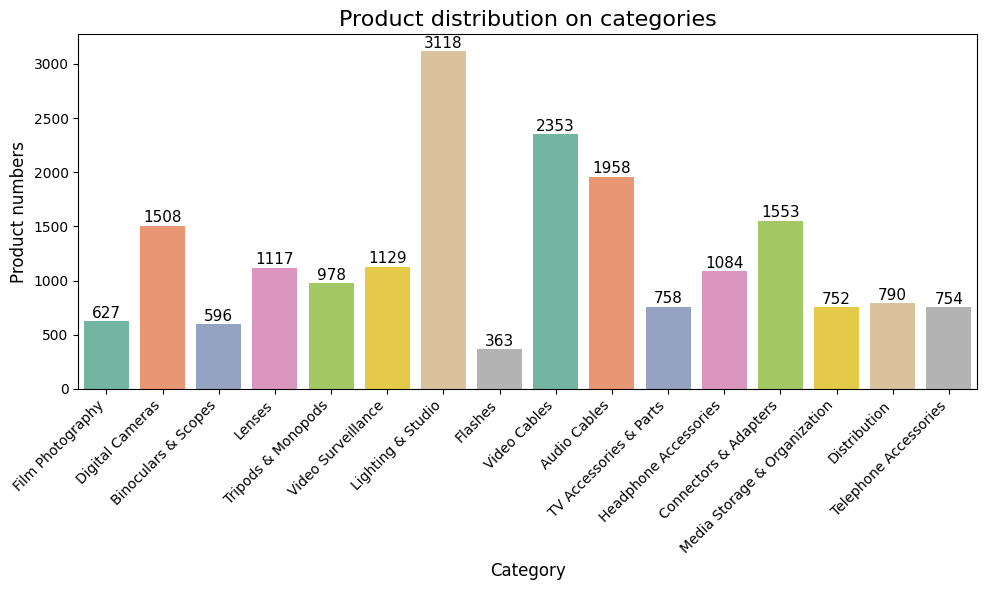

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

labels = data.y.numpy()
_, counts = np.unique(labels, return_counts=True)
class_names = []
with np.load(file_path) as loader:
    loader = dict(loader)
    class_names = loader['class_names']

plt.figure(figsize=(10, 6))
sns.barplot(x=class_names, y=counts, palette="Set2")
plt.title("Product distribution on categories", fontsize=16)
plt.xlabel("Category", fontsize=12)
plt.ylabel("Product numbers", fontsize=12)

for i, count in enumerate(counts):
    plt.text(i, count + max(counts)*0.01, str(count), ha='center', fontsize=11)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.savefig('distributie_clase.png', dpi=300)
plt.show()

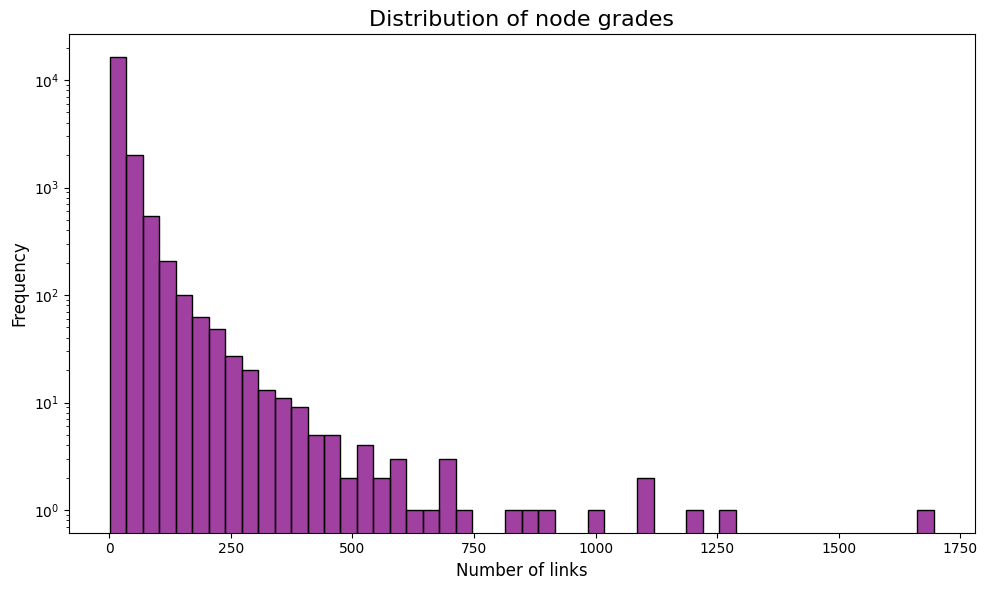

In [ ]:
import networkx as nx
from torch_geometric.utils import to_networkx

G = to_networkx(data, to_undirected=True)

degrees = [d for n, d in G.degree()]

plt.figure(figsize=(10, 6))
sns.histplot(degrees, bins=50, kde=False, color='purple')
plt.title("Distribution of node grades", fontsize=16)
plt.xlabel("Number of links", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.yscale('log')
plt.tight_layout()
plt.savefig('distributie_grade.png', dpi=300)
plt.show()

Calculez t-SNE pentru datele brute (TF-IDF)...


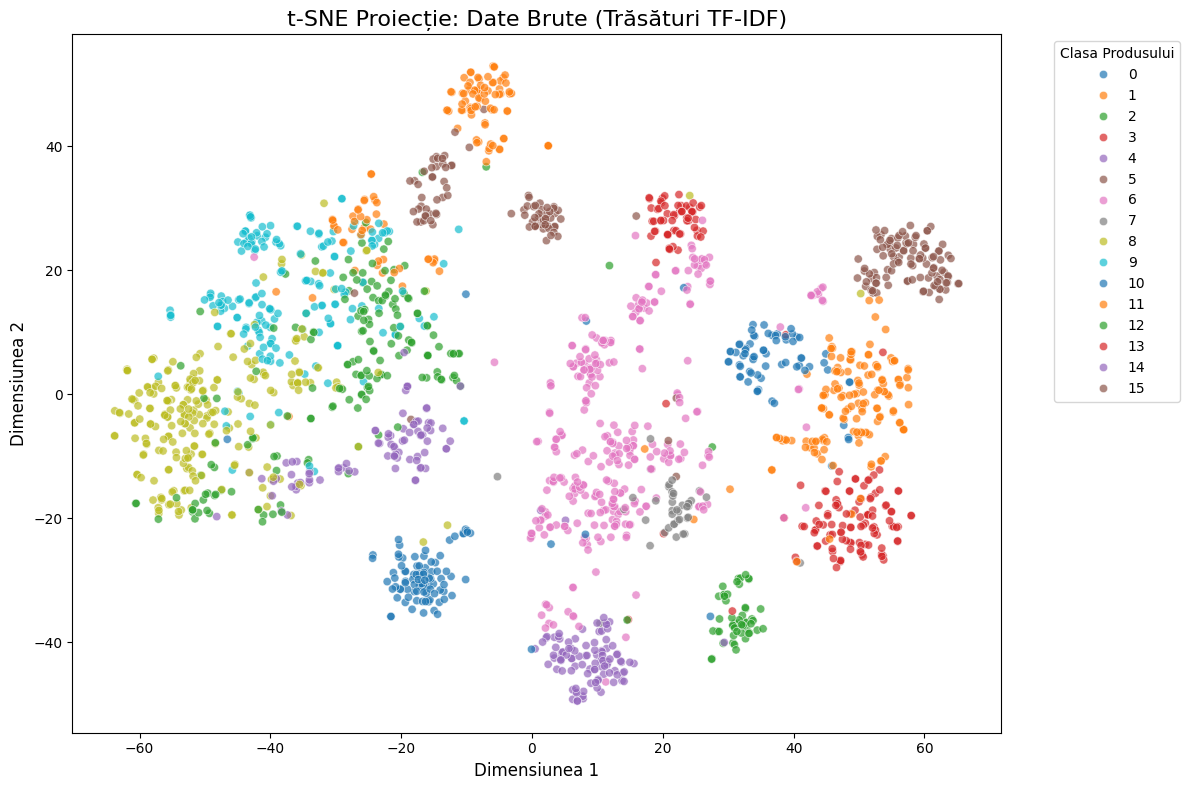

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# We take a sample to avoid waiting t-SNE
sample_size = min(2000, data.x.shape[0])
indices_sample = np.random.choice(data.x.shape[0], sample_size, replace=False)

X_sample_before = data.x.numpy()[indices_sample]
y_sample = data.y.numpy()[indices_sample]

# 2. Calculate t-SNE
tsne_before = TSNE(n_components=2, random_state=42)
X_tsne_before = tsne_before.fit_transform(X_sample_before)

# 3. Draw a single clean plot
plt.figure(figsize=(12, 8))
palette = sns.color_palette("tab10", len(np.unique(y_sample)))

sns.scatterplot(
    x=X_tsne_before[:, 0], y=X_tsne_before[:, 1],
    hue=y_sample, palette=palette,
    legend='full',
    alpha=0.7
)

plt.title("t-SNE Projection: Raw Data (SBERT Features)", fontsize=16)
plt.xlabel("Dimension 1", fontsize=12)
plt.ylabel("Dimension 2", fontsize=12)

plt.legend(title='Product Class', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)

plt.tight_layout()
plt.savefig('tsne_date_brute.png', dpi=300)
plt.show()

In [35]:
import typing
class GraphInfo:
    def __init__(self, edges: typing.Tuple[list, list], num_nodes: int):
        self.edges = edges
        self.num_nodes = num_nodes


In [ ]:

u, v = data.edge_index.numpy()

graph = GraphInfo(
    edges=(u.tolist(), v.tolist()),
    num_nodes=data.num_nodes
)

print(f"GraphInfo created: {graph.num_nodes} nodes, {len(graph.edges[0])} edges.")

GraphInfo creat: 19438 noduri, 387902 muchii.


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

class StrictGCNConv(layers.Layer):
    def __init__(self, in_feat, out_feat, graph_info, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.in_feat = in_feat
        self.out_feat = out_feat
        self.graph_info = graph_info

        self.weight = self.add_weight(
            initializer="glorot_uniform",
            shape=(in_feat, out_feat),
            dtype="float32",
            name="gcn_weight"
        )
        self.activation = layers.Activation(activation) if activation else None

    def call(self, features):
        # Linear transformation
        h = tf.matmul(features, self.weight)

        source_nodes = tf.convert_to_tensor(self.graph_info.edges[0], dtype=tf.int32)
        target_nodes = tf.convert_to_tensor(self.graph_info.edges[1], dtype=tf.int32)
        num_nodes = tf.cast(self.graph_info.num_nodes, tf.int32)

        # Add Self-Loops
        self_loops = tf.range(num_nodes, dtype=tf.int32)
        source_nodes = tf.concat([source_nodes, self_loops], axis=0)
        target_nodes = tf.concat([target_nodes, self_loops], axis=0)

        # Symmetric Normalization
        ones = tf.ones_like(source_nodes, dtype=tf.float32)
        deg = tf.math.unsorted_segment_sum(ones, target_nodes, num_segments=num_nodes)

        deg_inv_sqrt = tf.pow(deg, -0.5)
        deg_inv_sqrt = tf.where(tf.math.is_inf(deg_inv_sqrt), 0.0, deg_inv_sqrt)

        norm_source = tf.gather(deg_inv_sqrt, source_nodes)
        norm_target = tf.gather(deg_inv_sqrt, target_nodes)
        norm = norm_source * norm_target

        # Message Passing
        h_source = tf.gather(h, source_nodes)
        h_normalized = h_source * tf.expand_dims(norm, -1)

        # Final Aggregation
        aggregated = tf.math.unsorted_segment_sum(h_normalized, target_nodes, num_segments=num_nodes)

        return self.activation(aggregated) if self.activation else aggregated

In [ ]:
class StrictGCNModel(layers.Layer):
    def __init__(self, in_feat, out_feat, num_classes, graph_info, dropout=0.0, **kwargs):
        super().__init__(**kwargs)

        # First GCN layer
        self.gcn1 = StrictGCNConv(in_feat, out_feat, graph_info, activation="relu")
        self.ln1 = layers.LayerNormalization()
        self.drop1 = layers.Dropout(dropout)

        # Second GCN layer
        self.gcn2 = StrictGCNConv(out_feat, out_feat, graph_info, activation=None)
        self.ln2 = layers.LayerNormalization()
        self.drop2 = layers.Dropout(dropout)

        # Final classification
        self.dense = layers.Dense(num_classes, activation="softmax")

    def call(self, inputs, training=None):
        x = self.gcn1(inputs)
        x = self.ln1(x, training=training)
        x = self.drop1(x, training=training)

        x = self.gcn2(x)
        x = self.ln2(x, training=training)
        x = self.drop2(x, training=training)

        return self.dense(x)

In [ ]:
import tensorflow as tf
import keras

def focal_loss_custom(gamma=2.0):
    """
    Focal Loss that returns a vector per node.
    Keras multiplies each element by sample_weight before averaging — mathematically correct.
    """
    def loss_fn(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1. - epsilon)

        cross_entropy = keras.losses.sparse_categorical_crossentropy(y_true, y_pred)

        y_true_casted = tf.cast(y_true, tf.int32)
        batch_size    = tf.shape(y_pred)[0]
        indices       = tf.stack([tf.range(batch_size), y_true_casted], axis=1)
        p_t           = tf.gather_nd(y_pred, indices)

        modulating_factor = tf.pow(1.0 - p_t, gamma)

        return modulating_factor * cross_entropy

    return loss_fn

In [ ]:
import keras_tuner as kt

from sklearn.utils.class_weight import compute_class_weight

class_weights_raw = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_input),
    y=y_input[data.train_mask.numpy().astype(bool)]
)
class_weights = np.power(class_weights_raw, 0.5)
class_weight_dict = dict(enumerate(class_weights))
print(class_weight_dict)

combined_weight = train_weight.copy()
for cls, weight in class_weight_dict.items():
    combined_weight[y_input == cls] *= weight

def build_tuned_model(hp):
    out_feat = hp.Choice("out_feat", [16, 32, 64])
    lr       = hp.Float("lr", 1e-4, 1e-3, sampling="log")
    dropout  = hp.Float("dropout", 0.0, 0.4, step=0.1)

    inputs  = keras.Input((num_features,))
    outputs = StrictGCNModel(num_features, out_feat, 16, graph, dropout)(inputs)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer = keras.optimizers.Adam(learning_rate=lr),
        loss      = focal_loss_custom(gamma=2.0), 
        weighted_metrics = ["accuracy"]
    )
    return model

import shutil
shutil.rmtree("tuning_amazon_fixed", ignore_errors=True)

tuner = kt.BayesianOptimization(
    build_tuned_model,
    objective  = "val_loss",
    max_trials = 20,
    directory  = "tuning_amazon_fixed",
    project_name = "hybrid_v2"
)

tuner.search(
    X_input, y_input,
    sample_weight     = combined_weight,
    validation_data   = (X_input, y_input, val_weight),
    epochs            = 30,
    batch_size        = len(X_input),
    callbacks         = [keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)]
)

Trial 20 Complete [00h 00m 13s]
val_loss: 0.10993871837854385

Best val_loss So Far: 0.03934519365429878
Total elapsed time: 00h 05m 07s


Top 10 GCN tuning trials:


,trial_id,val_loss,out_feat,lr,dropout
17,17,0.039345,64,0.000810,0.3
16,16,0.039770,64,0.001000,0.0
9,09,0.040786,64,0.001000,0.1
13,13,0.041660,64,0.001000,0.3
10,10,0.041895,64,0.001000,0.4
18,18,0.042940,64,0.000837,0.3
5,05,0.044773,64,0.000555,0.3
15,15,0.048988,64,0.000624,0.2
12,12,0.049658,64,0.000530,0.0
14,14,0.074660,64,0.000432,0.4


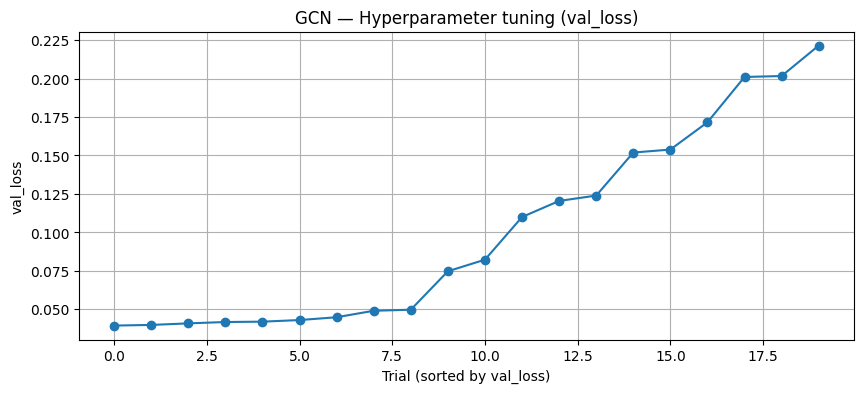

BEST GCN HP: {'out_feat': 64, 'lr': 0.0008099755387617071, 'dropout': 0.30000000000000004}


In [ ]:
import pandas as pd


rows = []
for t in tuner.oracle.trials.values():
    r = {"trial_id": t.trial_id, "val_loss": t.score}
    r.update(t.hyperparameters.values)
    rows.append(r)
gcn_tuning_df = pd.DataFrame(rows).sort_values("val_loss")

print("Top 10 GCN tuning trials:")
display(gcn_tuning_df.head(10))

plt.figure(figsize=(10,4))
plt.plot(gcn_tuning_df["val_loss"].values, marker="o")
plt.xlabel("Trial (sorted by val_loss)")
plt.ylabel("val_loss")
plt.title("GCN — Hyperparameter tuning (val_loss)")
plt.grid(True)
plt.show()

gcn_tuned = tuner.get_best_models(1)[0]
gcn_best_hp = tuner.get_best_hyperparameters(1)[0]
print("BEST GCN HP:", gcn_best_hp.values)


In [45]:
from sklearn import metrics as skmetrics

tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

best_hp = tuner.get_best_hyperparameters(1)[0]
print("Best hyperparameters:")
print(f"  out_feat:         {best_hp.get('out_feat')}")
print(f"  lr:               {best_hp.get('lr'):.6f}")
print(f"  dropout:          {best_hp.get('dropout')}")

best_model = tuner.hypermodel.build(best_hp)

best_model.fit(
    X_input, y_input,
    validation_data = (X_input, y_input, val_weight),
    sample_weight = combined_weight,
    batch_size    = len(X_input),
    epochs        = 100,
    callbacks     = [keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)]
)

Best hyperparameters:
  out_feat:         64
  lr:               0.000810
  dropout:          0.30000000000000004
Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.0730 - loss: 2.2001 - val_accuracy: 0.1111 - val_loss: 0.2524
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.0743 - loss: 1.9895 - val_accuracy: 0.1847 - val_loss: 0.2198
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.0837 - loss: 1.9084 - val_accuracy: 0.2562 - val_loss: 0.1948
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.0925 - loss: 1.8514 - val_accuracy: 0.3158 - val_loss: 0.1735
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.1028 - loss: 1.7875 - val_accuracy: 0.3904 - val_loss: 0.1562
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - accuracy: 0.1132 - loss: 1.7476 - val_accuracy: 0.4388 - val_loss: 0.1425
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.1223 - loss: 1.7078 - val_accuracy: 0.4691 - val_loss: 0.1310


In [ ]:
y_pred      = np.argmax(best_model.predict(X_input, batch_size=len(X_input)), axis=1)
test_mask   = data.test_mask.numpy().astype(bool)
y_pred_test = y_pred[test_mask]
y_true_test = y_input[test_mask]
print("FINAL RESULTS GCN MODEL")
print("Test set results:",
      "accu= {:.2f}".format(skmetrics.accuracy_score(y_true_test, y_pred_test) * 100),
      "macro_p= {:.2f}".format(skmetrics.precision_score(y_true_test, y_pred_test, average='macro') * 100),
      "macro_r= {:.2f}".format(skmetrics.recall_score(y_true_test, y_pred_test, average='macro') * 100),
      "macro_f1= {:.2f}".format(skmetrics.f1_score(y_true_test, y_pred_test, average='macro') * 100),
      "micro_f1= {:.2f}".format(skmetrics.f1_score(y_true_test, y_pred_test, average='micro') * 100))
print(skmetrics.classification_report(y_true_test, y_pred_test, digits=4))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Test set results: accu= 82.59 macro_p= 82.78 macro_r= 83.42 macro_f1= 82.85 micro_f1= 82.59
              precision    recall  f1-score   support

           0     0.8824    0.9574    0.9184       141
           1     0.8571    0.7770    0.8151       278
           2     0.9483    0.9402    0.9442       117
           3     0.7003    0.9043    0.7894       230
           4     0.8348    0.8698    0.8519       215
           5     0.9083    0.9776    0.9417       223
           6     0.9570    0.8797    0.9167       632
           7     0.5625    0.5696    0.5660        79
           8     0.7846    0.7830    0.7838       507
           9     0.6812    0.7839    0.7290       398
          10     0.9489    0.8784    0.9123       148
          11     0.8691    0.8469    0.8579       196
          12     0.7193    0.5413    0.6177       303
          13     0.9116    0.9853    0.9470       136
          14     0.7447    0.6908    0.7167       152
       

In [ ]:
import keras_tuner as kt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import shutil
import os

X_train_mlp = data.x[data.train_mask].numpy()
y_train_mlp = data.y[data.train_mask].numpy()

X_test_mlp = data.x[data.test_mask].numpy()
y_test_mlp = data.y[data.test_mask].numpy()

X_val_mlp = data.x[data.val_mask].numpy()
y_val_mlp = data.y[data.val_mask].numpy()

input_dim = X_train_mlp.shape[1]
num_classes = 16
folder_tuner = 'tuner_mlp_amazon'

if os.path.exists(folder_tuner):
    shutil.rmtree(folder_tuner)

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights_raw = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_input),
    y=y_input[data.train_mask.numpy().astype(bool)]
)
class_weights = np.power(class_weights_raw, 0.5)
class_weight_dict = dict(enumerate(class_weights))

def build_tuned_mlp(hp):
    model = keras.Sequential()
    model.add(layers.InputLayer(input_shape=(input_dim,)))

    hp_units1 = hp.Int('units_1', min_value=64, max_value=256, step=64)
    model.add(layers.Dense(units=hp_units1, activation='relu'))

    hp_drop1 = hp.Float('dropout_1', min_value=0.2, max_value=0.6, step=0.1)
    model.add(layers.Dropout(rate=hp_drop1))

    hp_units2 = hp.Int('units_2', min_value=32, max_value=128, step=32)
    model.add(layers.Dense(units=hp_units2, activation='relu'))

    hp_drop2 = hp.Float('dropout_2', min_value=0.1, max_value=0.5, step=0.1)
    model.add(layers.Dropout(rate=hp_drop2))

    model.add(layers.Dense(num_classes, activation='softmax'))

    hp_lr = hp.Choice('learning_rate', values=[1e-2, 5e-3, 1e-3])

    model.compile(
        optimizer        = keras.optimizers.Adam(learning_rate=hp_lr),
        loss             = focal_loss_custom(gamma=2.0),  
        weighted_metrics = ["accuracy"]                  
    )
    return model

tuner_mlp = kt.BayesianOptimization(
    build_tuned_mlp,
    objective    = 'val_loss',        
    max_trials   = 20,
    directory    = folder_tuner,
    project_name = 'mlp_baseline'
)

tuner_mlp.search(
    X_train_mlp, y_train_mlp,
    epochs            = 30,
    validation_data   = (X_val_mlp, y_val_mlp),
    class_weight      = class_weight_dict,   
    callbacks         = [keras.callbacks.EarlyStopping(
                            monitor='val_loss', patience=5, restore_best_weights=True)]
)

best_hps_mlp = tuner_mlp.get_best_hyperparameters(num_trials=1)[0]
print(f"\nBest hyperparameters for MLP baseline:")
print(f"1st layer units: {best_hps_mlp.get('units_1')}")
print(f"Dropout layer 1: {best_hps_mlp.get('dropout_1')}")
print(f"2nd layer units: {best_hps_mlp.get('units_2')}")
print(f"Dropout layer 2: {best_hps_mlp.get('dropout_2')}")
print(f"Learning Rate:   {best_hps_mlp.get('learning_rate')}")

best_mlp_model = tuner_mlp.hypermodel.build(best_hps_mlp)

history_best_mlp = best_mlp_model.fit(
    X_train_mlp, y_train_mlp,
    epochs          = 100,
    validation_data = (X_val_mlp, y_val_mlp),
    class_weight    = class_weight_dict,
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_loss', patience=10, restore_best_weights=True)]
)

from sklearn.metrics import classification_report

y_pred_mlp = best_mlp_model.predict(X_test_mlp).argmax(axis=1)

print("\n FINAL RESULTS MLP BASELINE")
print(classification_report(y_test_mlp, y_pred_mlp, digits=4))

Trial 20 Complete [00h 00m 15s]
val_loss: 0.16201624274253845

Best val_loss So Far: 0.1593625545501709
Total elapsed time: 00h 04m 04s

--- CEI MAI BUNI PARAMETRI GASITI ---
Neuroni strat 1: 128
Dropout strat 1: 0.30000000000000004
Neuroni strat 2: 64
Dropout strat 2: 0.2
Learning Rate:   0.001
Epoch 1/100
426/426 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7250 - loss: 0.6080 - val_accuracy: 0.8709 - val_loss: 0.2232
Epoch 2/100
426/426 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8618 - loss: 0.2265 - val_accuracy: 0.8853 - val_loss: 0.1908
Epoch 3/100
426/426 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8768 - loss: 0.1926 - val_accuracy: 0.8853 - val_loss: 0.1837
Epoch 4/100
426/426 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8877 - loss: 0.1700 - val_accuracy: 0.8889 - val_loss: 0.1750
Epoch 5/100
426/426 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8913 - loss: 0.1530 - val_accuracy: 0.8909 - val_loss: 0.1752
Epoch 6/100
426/426 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - acc

In [ ]:
import numpy as np
import tensorflow as tf

X_full = data.x.numpy()
y_full = data.y.numpy()

num_nodes = X_full.shape[0]
self_loops = np.vstack((np.arange(num_nodes), np.arange(num_nodes)))
edges_with_loops = np.hstack((data.edge_index.numpy(), self_loops))

edge_index_tf = tf.convert_to_tensor(edges_with_loops, dtype=tf.int32)

input_dim = X_full.shape[1]
num_classes = 16

train_mask = data.train_mask.numpy().astype(bool)
val_mask   = data.val_mask.numpy().astype(bool)
test_mask  = data.test_mask.numpy().astype(bool)

train_weights = np.zeros(X_full.shape[0])
train_weights[train_mask] = 1.0

val_weights = np.zeros(X_full.shape[0])
val_weights[val_mask] = 1.0

print(f"The graph now has {edge_index_tf.shape[1]} edges (including self-loops).")

Date pregătite! Graful are acum 407340 muchii (inclusiv self-loops).


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf

class StaticGraphAttn(layers.Layer):
    def __init__(self, in_feat, out_feat, edge_index, dropout_rate=0.0, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.edge_index = edge_index

        self.W = self.add_weight(shape=(in_feat, out_feat), initializer="glorot_uniform", trainable=True, name="W")
        self.a = self.add_weight(shape=(2 * out_feat, 1), initializer="glorot_uniform", trainable=True, name="a")

        self.leaky = layers.LeakyReLU(0.2)
        self.attn_dropout = layers.Dropout(dropout_rate)
        self.activation = layers.Activation(activation) if activation else None

    def call(self, features, training=None):
        src = self.edge_index[0]
        dst = self.edge_index[1]
        N = tf.shape(features)[0]

        # Liniar transformation
        h = tf.matmul(features, self.W)

        # Compute attention coefficients
        h_i = tf.gather(h, dst)
        h_j = tf.gather(h, src)

        # Compute attention scores
        e = tf.squeeze(tf.matmul(tf.concat([h_i, h_j], axis=-1), self.a), axis=-1)
        e = self.leaky(e)

        # Compute softmax normalization
        max_e = tf.math.unsorted_segment_max(e, dst, N)
        max_e_edges = tf.gather(max_e, dst)
        exp_e = tf.exp(e - max_e_edges)
        sum_exp = tf.math.unsorted_segment_sum(exp_e, dst, N)
        alpha = exp_e / (tf.gather(sum_exp, dst) + 1e-9)

        alpha = self.attn_dropout(alpha, training=training)
        # Aggregate messages
        messages = tf.expand_dims(alpha, -1) * h_j
        # Sum the messages for each node
        out = tf.math.unsorted_segment_sum(messages, dst, N)

        return self.activation(out) if self.activation else out

In [ ]:
class MultiHeadStaticGAT(layers.Layer):
    def __init__(self, num_heads, in_feat, out_feat, edge_index, dropout_rate=0.0, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.heads = [
            StaticGraphAttn(in_feat, out_feat, edge_index, dropout_rate=dropout_rate, activation=activation)
            for _ in range(num_heads)
        ]
        self.feature_dropout = layers.Dropout(dropout_rate)

    def call(self, features, training=None):
        head_outputs = [head(features, training=training) for head in self.heads]

        x = tf.concat(head_outputs, axis=-1)
        x = self.feature_dropout(x, training=training)

        return x

In [51]:

tf.random.set_seed(42)

def build_tuned_gat(hp):
    hp_heads = hp.Choice("num_heads", [2, 4, 8])
    hp_out_feat = hp.Choice("out_feat", [8, 16, 32])
    hp_lr = hp.Float("lr", min_value=1e-4, max_value=5e-3, sampling="log")
    hp_dropout = hp.Float("dropout", 0.0, 0.4, step=0.1)

    model = keras.Sequential()
    model.add(layers.InputLayer(input_shape=(input_dim,)))

    model.add(MultiHeadStaticGAT(
        num_heads=hp_heads,
        in_feat=input_dim,
        out_feat=hp_out_feat,
        edge_index=edge_index_tf,
        dropout_rate=hp_dropout,
        activation='relu'
    ))
    model.add(StaticGraphAttn(in_feat=hp_heads*hp_out_feat, out_feat=hp_out_feat, 
                          edge_index=edge_index_tf, dropout_rate=hp_dropout, activation=None))

    model.add(layers.Dense(num_classes, activation='softmax'))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=hp_lr),
        loss=focal_loss_custom(gamma=2.0),
        weighted_metrics=["accuracy"]
    )

    return model


In [ ]:
import os
import shutil
import pandas as pd
import keras_tuner as kt
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report


y_train_only = y_full[train_mask]

class_weights_raw = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_only),
    y=y_train_only
)
class_weights = np.power(class_weights_raw, 0.5)
class_weight_dict = dict(enumerate(class_weights))

for cls, w in class_weight_dict.items():
    print(f"Class {cls}: {w:.2f}")

train_weights_balanced = train_weights.copy()
for cls, weight in class_weight_dict.items():
    train_weights_balanced[y_full == cls] *= weight

folder_tuner_gat = 'tuner_gat_amazon'
if os.path.exists(folder_tuner_gat):
    shutil.rmtree(folder_tuner_gat)

tuner_gat = kt.BayesianOptimization(
    build_tuned_gat,
    objective='val_loss',
    max_trials=20,
    directory=folder_tuner_gat,
    project_name='gat_amazon'
)

tuner_gat.search(
    X_full, y_full,
    sample_weight=train_weights_balanced,
    epochs=30,
    batch_size=X_full.shape[0],
    shuffle=False,
    validation_data=(X_full, y_full, val_weights),
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)],
)


best_hps_gat = tuner_gat.get_best_hyperparameters(num_trials=1)[0]
print(f"\n BEST GAT HYPERPARAMETERS FOUND")
print(f"Number of Heads: {best_hps_gat.get('num_heads')}")
print(f"Features per Head: {best_hps_gat.get('out_feat')}")
print(f"Dropout Rate: {best_hps_gat.get('dropout')}")
print(f"Learning Rate: {best_hps_gat.get('lr'):.6f}")

best_gat_model = tuner_gat.hypermodel.build(best_hps_gat)

history_best_gat = best_gat_model.fit(
    X_full, y_full,
    sample_weight=train_weights_balanced,
    epochs=150,
    batch_size=X_full.shape[0],
    shuffle=False,
    validation_data=(X_full, y_full, val_weights),
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)],
)


Trial 20 Complete [00h 00m 23s]
val_loss: 0.046212486922740936

Best val_loss So Far: 0.0343497171998024
Total elapsed time: 00h 07m 24s

--- CEI MAI BUNI PARAMETRI GAT GASIȚI ---
Număr Capete (Heads): 8
Features per Capăt: 32
Rata Dropout: 0.4
Learning Rate: 0.005000
Epoch 1/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.0403 - loss: 1.6460 - val_accuracy: 0.5113 - val_loss: 0.2233
Epoch 2/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 789ms/step - accuracy: 0.4239 - loss: 1.5204 - val_accuracy: 0.5273 - val_loss: 0.2008
Epoch 3/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 795ms/step - accuracy: 0.4483 - loss: 1.3842 - val_accuracy: 0.5324 - val_loss: 0.1739
Epoch 4/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 790ms/step - accuracy: 0.4540 - loss: 1.2261 - val_accuracy: 0.5406 - val_loss: 0.1464
Epoch 5/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 797ms/step - accuracy: 0.4650 - loss: 1.0742 - val_accuracy: 0.5741 - val_loss: 0.1217
Epoch 6/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 795ms/step - accuracy: 0.5105 - loss: 0.9221 - val_accuracy

Top 10 GAT tuning trials:


,trial_id,val_loss,num_heads,out_feat,lr,dropout
13,13,0.034350,8,32,0.005000,0.4
15,15,0.034815,8,32,0.005000,0.2
12,12,0.034988,8,32,0.005000,0.0
14,14,0.035593,4,32,0.005000,0.2
17,17,0.036279,2,32,0.005000,0.4
18,18,0.036563,2,32,0.005000,0.0
19,19,0.046212,8,8,0.005000,0.0
1,01,0.050837,8,32,0.001348,0.1
11,11,0.057076,8,16,0.002104,0.0
10,10,0.071769,4,8,0.004630,0.3


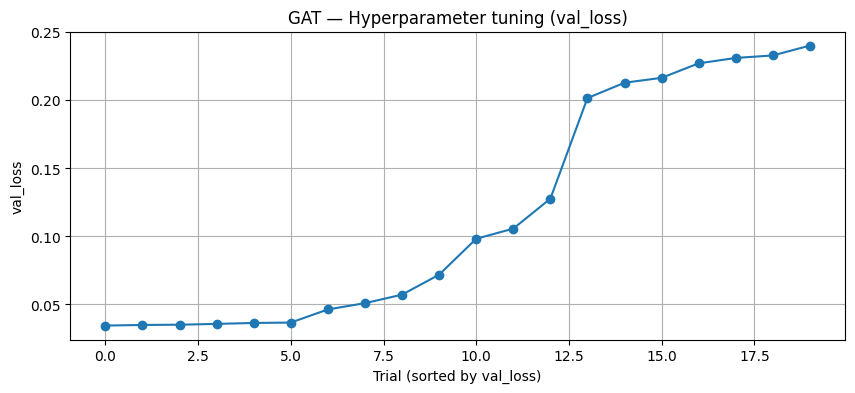

BEST GAT HP: {'num_heads': 8, 'out_feat': 32, 'lr': 0.005, 'dropout': 0.4}


In [53]:
rows = []
for t in tuner_gat.oracle.trials.values():
    r = {"trial_id": t.trial_id, "val_loss": t.score}
    r.update(t.hyperparameters.values)
    rows.append(r)
gat_tuning_df = pd.DataFrame(rows).sort_values("val_loss")

print("Top 10 GAT tuning trials:")
display(gat_tuning_df.head(10))

plt.figure(figsize=(10,4))
plt.plot(gat_tuning_df["val_loss"].values, marker="o")
plt.xlabel("Trial (sorted by val_loss)")
plt.ylabel("val_loss")
plt.title("GAT — Hyperparameter tuning (val_loss)")
plt.grid(True)
plt.show()

gat_best_hp = tuner_gat.get_best_hyperparameters(1)[0]
print("BEST GAT HP:", gat_best_hp.values)

In [ ]:
from sklearn.metrics import classification_report
from sklearn import metrics as skmetrics

y_pred_probs_gat = best_gat_model.predict(X_full, batch_size=X_full.shape[0])
y_pred_gat_full = y_pred_probs_gat.argmax(axis=1)

y_test_true = y_full[test_mask]
y_test_pred = y_pred_gat_full[test_mask]

print("Test set results:",
      "accu= {:.2f}".format(skmetrics.accuracy_score(y_test_true, y_test_pred) * 100),
      "macro_p= {:.2f}".format(skmetrics.precision_score(y_test_true, y_test_pred, average='macro') * 100),
      "macro_r= {:.2f}".format(skmetrics.recall_score(y_test_true, y_test_pred, average='macro') * 100),
      "macro_f1= {:.2f}".format(skmetrics.f1_score(y_test_true, y_test_pred, average='macro') * 100),
      "micro_f1= {:.2f}".format(skmetrics.f1_score(y_test_true, y_test_pred, average='micro') * 100))

print("\n FINAL RESULTS GAT MODEL")
print(classification_report(y_test_true, y_test_pred, digits=4))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 418ms/step
Test set results: accu= 84.23 macro_p= 84.52 macro_r= 84.47 macro_f1= 84.42 micro_f1= 84.23

=== REZULTATE FINALE GAT BAYESIAN (TEST SET) ===
              precision    recall  f1-score   support

           0     0.9291    0.9291    0.9291       141
           1     0.8261    0.8885    0.8562       278
           2     0.9561    0.9316    0.9437       117
           3     0.8341    0.7870    0.8098       230
           4     0.8354    0.9209    0.8761       215
           5     0.9643    0.9686    0.9664       223
           6     0.9434    0.9225    0.9328       632
           7     0.5412    0.5823    0.5610        79
           8     0.7827    0.8028    0.7926       507
           9     0.7283    0.7814    0.7539       398
          10     0.9296    0.8919    0.9103       148
          11     0.8653    0.8520    0.8586       196
          12     0.6758    0.5710    0.6190       303
          13     0.9853    0.9853    0.9853       136
        

In [ ]:
import numpy as np
import tensorflow as tf

X_full = data.x.numpy()
y_full = data.y.numpy()

edge_index_tf = tf.convert_to_tensor(data.edge_index.numpy(), dtype=tf.int32)

input_dim = X_full.shape[1]
num_classes = 16

train_mask = data.train_mask.numpy().astype(bool)
val_mask   = data.val_mask.numpy().astype(bool)
test_mask  = data.test_mask.numpy().astype(bool)

train_weights = np.zeros(X_full.shape[0])
train_weights[train_mask] = 1.0

val_weights = np.zeros(X_full.shape[0])
val_weights[val_mask] = 1.0

X_train_inductive = X_full.copy()
mask_not_train = ~train_mask
X_train_inductive[mask_not_train] = 0.0

Date pregătite pentru GraphSAGE! Graful are 387902 muchii.
Am ascuns (zero features) pentru 5832 noduri pentru a testa generalizarea inductivă.


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

class SAGEConvLayer(layers.Layer):
    def __init__(self, out_feat, edge_index, normalize=True, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.out_feat   = out_feat
        self.edge_index = edge_index
        self.normalize  = normalize

        self.W          = layers.Dense(out_feat, use_bias=False, kernel_initializer="glorot_uniform")
        self.activation = layers.Activation(activation) if activation else None

    def call(self, features, training=None):
        src       = self.edge_index[0]
        dst       = self.edge_index[1]
        num_nodes = tf.shape(features)[0]

        neighbor_features    = tf.gather(features, src)
        # Compute the mean of neighbor features for each destination node
        aggregated_neighbors = tf.math.unsorted_segment_mean(
            neighbor_features, dst, num_segments=num_nodes
        )

        # Combine the original features with the aggregated neighbor features
        combined = tf.concat([features, aggregated_neighbors], axis=-1)
        out      = self.W(combined)
        
        # Apply activation and normalization if specified
        if self.activation:
            out = self.activation(out)
        if self.normalize:
            out = tf.math.l2_normalize(out, axis=-1)

        return out

In [15]:
class StaticGraphSAGE(layers.Layer):
    def __init__(self, out_feat, edge_index, dropout_rate=0.0, normalize=True, final_activation='relu', **kwargs):
        super().__init__(**kwargs)
        self.conv1 = SAGEConvLayer(out_feat, edge_index, normalize=False, activation='relu')
        self.conv2 = SAGEConvLayer(out_feat, edge_index, normalize=normalize, activation=final_activation)

        self.drop1 = layers.Dropout(dropout_rate)
        self.drop2 = layers.Dropout(dropout_rate)

    def call(self, features, training=None):
        x = self.drop1(features, training=training)
        x = self.conv1(x, training=training)
        x = self.drop2(x, training=training)
        x = self.conv2(x, training=training)
        return x

In [ ]:
import os
import shutil
import pandas as pd

tf.random.set_seed(42)

def build_tuned_sage(hp):
    hp_out_feat = hp.Choice("out_feat", [16, 32, 64])
    hp_lr = hp.Float("lr", min_value=1e-4, max_value=5e-3, sampling="log")
    hp_dropout = hp.Float("dropout", 0.0, 0.5, step=0.1)

    hp_normalize = hp.Boolean("normalize", default=True)

    model = keras.Sequential()
    model.add(layers.InputLayer(input_shape=(input_dim,)))

    model.add(StaticGraphSAGE(
        out_feat=hp_out_feat,
        edge_index=edge_index_tf,
        dropout_rate=hp_dropout,
        normalize=hp_normalize
    ))

    model.add(layers.Dense(num_classes, activation='softmax'))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=hp_lr),
        loss=focal_loss_custom(gamma=2.0),
        weighted_metrics=["accuracy"]
    )
    return model


folder_tuner_sage = 'tuner_sage_amazon'
if os.path.exists(folder_tuner_sage):
    shutil.rmtree(folder_tuner_sage)

y_train_only = y_full[train_mask]
class_weights_raw = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_only),
    y=y_train_only
)
class_weights = np.power(class_weights_raw, 0.5) 
class_weight_dict = dict(enumerate(class_weights))

for cls, w in class_weight_dict.items():
    print(f"Class {cls}: {w:.2f}")

train_weights_balanced = train_weights.copy()
for cls, weight in class_weight_dict.items():
    train_weights_balanced[y_full == cls] *= weight

tuner_sage = kt.BayesianOptimization(
    build_tuned_sage,
    objective='val_loss',
    max_trials=20,
    directory=folder_tuner_sage,
    project_name='sage_amazon'
)

tuner_sage.search(
    X_train_inductive, y_full,
    sample_weight=train_weights_balanced,
    epochs=30,
    batch_size=X_full.shape[0],
    shuffle=False,
    validation_data=(X_train_inductive, y_full, val_weights),
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)],
)


best_hps_sage = tuner_sage.get_best_hyperparameters(num_trials=1)[0]
print(f"\n BEST SAGE HYPERPARAMETERS FOUND")
print(f"Features: {best_hps_sage.get('out_feat')}")
print(f"Dropout Rate: {best_hps_sage.get('dropout')}")
print(f"Normalize L2: {best_hps_sage.get('normalize')}")
print(f"Learning Rate: {best_hps_sage.get('lr'):.6f}")

best_sage_model = tuner_sage.hypermodel.build(best_hps_sage)

history_best_sage = best_sage_model.fit(
    X_train_inductive, y_full,
    sample_weight=train_weights_balanced,
    epochs=150,
    batch_size=X_full.shape[0],
    shuffle=False,
    validation_data=(X_train_inductive, y_full, val_weights),
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)],
)

Trial 20 Complete [00h 00m 13s]
val_loss: 0.052786845713853836

Best val_loss So Far: 0.05132323130965233
Total elapsed time: 00h 04m 29s

--- CEI MAI BUNI PARAMETRI GraphSAGE GASIȚI ---
Features: 64
Rata Dropout: 0.4
Normalize L2: False
Learning Rate: 0.005000
Epoch 1/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.0587 - loss: 1.6486 - val_accuracy: 0.4450 - val_loss: 0.2396
Epoch 2/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 284ms/step - accuracy: 0.3631 - loss: 1.6014 - val_accuracy: 0.5031 - val_loss: 0.2317
Epoch 3/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step - accuracy: 0.4472 - loss: 1.5203 - val_accuracy: 0.4918 - val_loss: 0.2196
Epoch 4/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - accuracy: 0.4548 - loss: 1.4019 - val_accuracy: 0.4743 - val_loss: 0.2030
Epoch 5/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 286ms/step - accuracy: 0.4447 - loss: 1.2553 - val_accuracy: 0.4794 - val_loss: 0.1831
Epoch 6/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - accuracy: 0.4442 - loss: 1.0935 - val_accuracy: 0.535

Top 10 SAGE tuning trials:


,trial_id,val_loss,out_feat,lr,dropout,normalize
12,12,0.051323,64,0.005000,0.4,False
17,17,0.051632,64,0.005000,0.4,False
18,18,0.052741,64,0.005000,0.4,False
19,19,0.052787,64,0.005000,0.4,False
16,16,0.052937,64,0.005000,0.4,False
15,15,0.054321,64,0.005000,0.4,False
13,13,0.054850,64,0.005000,0.3,False
5,05,0.075937,64,0.001890,0.3,False
14,14,0.114583,64,0.005000,0.4,True
11,11,0.187286,16,0.002304,0.3,True


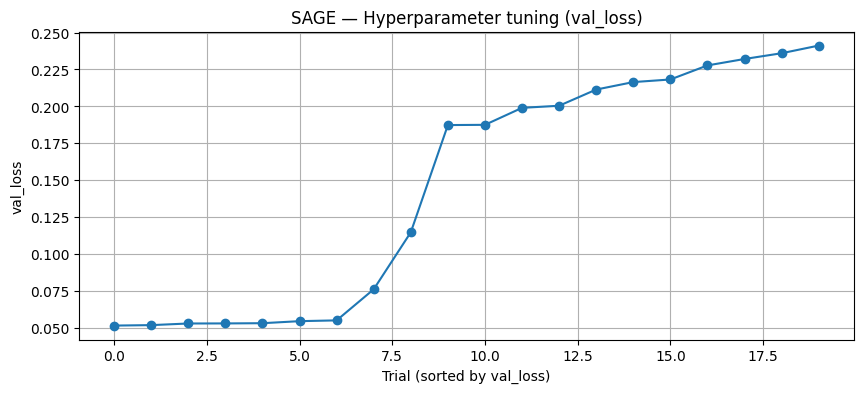

BEST SAGE HP: {'out_feat': 64, 'lr': 0.005, 'dropout': 0.4, 'normalize': False}


In [59]:
rows = []
for t in tuner_sage.oracle.trials.values():
    r = {"trial_id": t.trial_id, "val_loss": t.score}
    r.update(t.hyperparameters.values)
    rows.append(r)
sage_tuning_df = pd.DataFrame(rows).sort_values("val_loss")

print("Top 10 SAGE tuning trials:")
display(sage_tuning_df.head(10))

plt.figure(figsize=(10,4))
plt.plot(sage_tuning_df["val_loss"].values, marker="o")
plt.xlabel("Trial (sorted by val_loss)")
plt.ylabel("val_loss")
plt.title("SAGE — Hyperparameter tuning (val_loss)")
plt.grid(True)
plt.show()

sage_tuned = tuner_sage.get_best_models(1)[0]
sage_best_hp = tuner_sage.get_best_hyperparameters(1)[0]
print("BEST SAGE HP:", sage_best_hp.values)

In [ ]:
from sklearn import metrics as skmetrics
from sklearn.metrics import classification_report

y_pred_probs_sage = best_sage_model.predict(X_full, batch_size=X_full.shape[0])
y_pred_sage_full = y_pred_probs_sage.argmax(axis=1)

y_test_true = y_full[test_mask]
y_test_pred = y_pred_sage_full[test_mask]

print("Test set results:",
      "accu= {:.2f}".format(skmetrics.accuracy_score(y_test_true, y_test_pred) * 100),
      "macro_p= {:.2f}".format(skmetrics.precision_score(y_test_true, y_test_pred, average='macro') * 100),
      "macro_r= {:.2f}".format(skmetrics.recall_score(y_test_true, y_test_pred, average='macro') * 100),
      "macro_f1= {:.2f}".format(skmetrics.f1_score(y_test_true, y_test_pred, average='macro') * 100),
      "micro_f1= {:.2f}".format(skmetrics.f1_score(y_test_true, y_test_pred, average='micro') * 100))

print("\n FINAL RESULTS SAGE MODEL")
print(classification_report(y_test_true, y_test_pred, digits=4))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
Test set results: accu= 84.16 macro_p= 85.00 macro_r= 84.12 macro_f1= 84.37 micro_f1= 84.16

=== REZULTATE FINALE GraphSage (TEST SET) ===
              precision    recall  f1-score   support

           0     0.8993    0.9504    0.9241       141
           1     0.8279    0.9173    0.8703       278
           2     0.9474    0.9231    0.9351       117
           3     0.8879    0.8609    0.8742       230
           4     0.7912    0.9163    0.8491       215
           5     0.9731    0.9731    0.9731       223
           6     0.9517    0.9051    0.9278       632
           7     0.6774    0.5316    0.5957        79
           8     0.7711    0.8304    0.7996       507
           9     0.6970    0.7513    0.7231       398
          10     0.9559    0.8784    0.9155       148
          11     0.8291    0.8418    0.8354       196
          12     0.7042    0.5578    0.6225       303
          13     0.9852    0.9779    0.9815       136
          1

# **LINK PREDICTION**

In [ ]:
import torch_geometric.transforms as T


X_full = data.x.numpy()
y_full = data.y.numpy()

link_split = T.RandomLinkSplit(
    num_val=0.1,
    num_test=0.1,
    is_undirected=True,
    add_negative_train_samples=True,
    disjoint_train_ratio=0.0,
    neg_sampling_ratio=1.0
)

train_data, val_data, test_data = link_split(data)

print("SPLIT FOR LINK PREDICTION")
print(f"Edges for Training (Real + False): {train_data.edge_label_index.shape[1]}")
print(f"Edges for Validation (Real + False): {val_data.edge_label_index.shape[1]}")
print(f"Edges for Testing (Real + False): {test_data.edge_label_index.shape[1]}")

=== SPLIT PENTRU LINK PREDICTION ===
Muchii pentru Antrenament (Reale + False): 310322
Muchii pentru Validare (Reale + False): 38790
Muchii pentru Testare (Reale + False): 38790

Structura noului 'train_data':
- edge_index (Muchiile folosite DOAR pentru a transmite mesaje): torch.Size([2, 310322])
- edge_label_index (Perechile de noduri pe care modelul e testat): torch.Size([2, 310322])
- edge_label (Etichetele 1=Muchi reală, 0=Muchie falsă): torch.Size([310322])


In [ ]:
import tensorflow as tf

edge_index_train_np = train_data.edge_index.numpy()

# Symmetrize the edges for message passing
src, dst = edge_index_train_np[0], edge_index_train_np[1]
sym_src = np.concatenate([src, dst])
sym_dst = np.concatenate([dst, src])

# Remove duplicates
sym_edges = np.unique(np.stack([sym_src, sym_dst], axis=0), axis=1)
edge_index_train_tf = tf.convert_to_tensor(sym_edges, dtype=tf.int32)

# Convert the edge labels for training, validation, and testing
edge_label_index_train_tf = tf.convert_to_tensor(train_data.edge_label_index.numpy(), dtype=tf.int32)
y_train_link = tf.convert_to_tensor(train_data.edge_label.numpy(), dtype=tf.float32)

edge_label_index_val_tf = tf.convert_to_tensor(val_data.edge_label_index.numpy(), dtype=tf.int32)
y_val_link = tf.convert_to_tensor(val_data.edge_label.numpy(), dtype=tf.float32)

edge_label_index_test_tf = tf.convert_to_tensor(test_data.edge_label_index.numpy(), dtype=tf.int32)
y_test_link = tf.convert_to_tensor(test_data.edge_label.numpy(), dtype=tf.float32)


Conversia PyTorch -> TensorFlow realizată! Muchii msg-passing (simetrizate): 310322


In [ ]:
def generate_hard_negatives(edge_index_np, num_nodes, num_negatives, node_features, k_candidates=50, rng_num=42):
    """
    Generate hard negatives: pairs of nodes that are NOT connected
    but have HIGH feature similarity (cosine).
    """
    from sklearn.metrics.pairwise import cosine_similarity
    
    # Build adjacency set for fast lookup
    adj_set = set()
    src, dst = edge_index_np[0], edge_index_np[1]
    for s, d in zip(src, dst):
        adj_set.add((int(s), int(d)))
        adj_set.add((int(d), int(s)))
    
    rng = np.random.default_rng(rng_num)
    
    # Sample source nodes with replacement so we can exceed num_nodes
    pool_size = max(num_negatives * 2, num_nodes)
    candidate_sources = rng.choice(num_nodes, size=pool_size, replace=True)
    
    hard_neg_src = []
    hard_neg_dst = []
    sim_cache = {}  # cache cosine sim per source node
    
    for s in candidate_sources:
        if len(hard_neg_src) >= num_negatives:
            break
        s = int(s)
        
        # Compute similarities once per source node
        if s not in sim_cache:
            sim = cosine_similarity(node_features[s:s+1], node_features)[0]
            sim_cache[s] = np.argsort(sim)[::-1][1:k_candidates+1]
        top_k_indices = sim_cache[s]
        
        # Pick the most similar node that is NOT a neighbor and NOT already picked
        for candidate in top_k_indices:
            c = int(candidate)
            if c != s and (s, c) not in adj_set:
                hard_neg_src.append(s)
                hard_neg_dst.append(c)
                adj_set.add((s, c))  # prevent duplicate hard negative
                break
    
    hard_neg_src = np.array(hard_neg_src[:num_negatives])
    hard_neg_dst = np.array(hard_neg_dst[:num_negatives])
    
    return hard_neg_src, hard_neg_dst

In [ ]:
import numpy as np
import tensorflow as tf

# Number of hard negatives = 30% of existing negative train samples
num_pos_train = int(y_train_link.numpy().sum())
num_neg_train = len(y_train_link) - num_pos_train
num_hard = int(num_neg_train * 0.3)

print(f"Generating {num_hard} hard negatives (30% of {num_neg_train} easy negatives)...")

hard_src, hard_dst = generate_hard_negatives(
    edge_index_np=train_data.edge_index.numpy(),
    num_nodes=X_full.shape[0],
    num_negatives=num_hard,
    node_features=X_full,
    k_candidates=30
)

print(f"Generated {len(hard_src)} hard negatives.")

# Combine with existing train edges
hard_neg_edges = np.stack([hard_src, hard_dst], axis=0)  
hard_neg_labels = np.zeros(len(hard_src), dtype=np.float32)

# Augment training data
edge_label_index_augmented = tf.concat([
    edge_label_index_train_tf,
    tf.convert_to_tensor(hard_neg_edges, dtype=tf.int32)
], axis=1)

y_train_link_augmented = tf.concat([
    y_train_link,
    tf.convert_to_tensor(hard_neg_labels, dtype=tf.float32)
], axis=0)

x_train_edges_augmented = tf.transpose(edge_label_index_augmented)

print(f"Training edges after augmentation: {x_train_edges_augmented.shape[0]} "
      f"(was {len(y_train_link)}, added {len(hard_src)} hard negatives)")
print(f"Positive ratio: {y_train_link_augmented.numpy().mean():.3f}")

Generating 46548 hard negatives (30% of 155161 easy negatives)...
Generated 46548 hard negatives.
Training edges after augmentation: 356870 (was 310322, added 46548 hard negatives)
Positive ratio: 0.435


In [ ]:

num_pos_test = int(y_test_link.numpy().sum())
num_neg_test = len(y_test_link) - num_pos_test
num_hard_test = int(num_neg_test * 0.3)

print(f"Generating {num_hard_test} hard negatives for TEST set (30% of {num_neg_test} easy negatives)...")

hard_src_test, hard_dst_test = generate_hard_negatives(
    edge_index_np=train_data.edge_index.numpy(),
    num_nodes=X_full.shape[0],
    num_negatives=num_hard_test,
    node_features=X_full,
    k_candidates=30,
    rng_num=123  
)

print(f"Generated {len(hard_src_test)} hard negatives for test.")

hard_neg_edges_test = np.stack([hard_src_test, hard_dst_test], axis=0)
hard_neg_labels_test = np.zeros(len(hard_src_test), dtype=np.float32)

# Augment test data
edge_label_index_test_augmented = tf.concat([
    edge_label_index_test_tf,
    tf.convert_to_tensor(hard_neg_edges_test, dtype=tf.int32)
], axis=1)

y_test_link_augmented = tf.concat([
    y_test_link,
    tf.convert_to_tensor(hard_neg_labels_test, dtype=tf.float32)
], axis=0)

# Marker for separating easy vs hard negatives in reporting
test_is_hard_neg = tf.concat([
    tf.zeros(len(y_test_link), dtype=tf.bool),
    tf.ones(len(hard_src_test), dtype=tf.bool)
], axis=0)

print(f"Test edges after augmentation: {edge_label_index_test_augmented.shape[1]} "
      f"(was {len(y_test_link)}, added {len(hard_src_test)} hard negatives)")
print(f"Test positive ratio: {y_test_link_augmented.numpy().mean():.3f}")

Generating 5818 hard negatives for TEST set (30% of 19395 easy negatives)...
Generated 5818 hard negatives for test.
Test edges after augmentation: 44608 (was 38790, added 5818 hard negatives)
Test positive ratio: 0.435


In [ ]:

num_pos_val = int(y_val_link.numpy().sum())
num_neg_val = len(y_val_link) - num_pos_val
num_hard_val = int(num_neg_val * 0.3)

print(f"Generating {num_hard_val} hard negatives for VAL set (30% of {num_neg_val} easy negatives)...")

hard_src_val, hard_dst_val = generate_hard_negatives(
    edge_index_np=train_data.edge_index.numpy(),  
    num_nodes=X_full.shape[0],
    num_negatives=num_hard_val,
    node_features=X_full,
    k_candidates=30,
    rng_num=456  # different seed for val set to ensure different negatives
)

print(f"Generated {len(hard_src_val)} hard negatives for val.")

hard_neg_edges_val = np.stack([hard_src_val, hard_dst_val], axis=0)
hard_neg_labels_val = np.zeros(len(hard_src_val), dtype=np.float32)

# Augment validation data
edge_label_index_val_augmented = tf.concat([
    edge_label_index_val_tf,
    tf.convert_to_tensor(hard_neg_edges_val, dtype=tf.int32)
], axis=1)

y_val_link_augmented = tf.concat([
    y_val_link,
    tf.convert_to_tensor(hard_neg_labels_val, dtype=tf.float32)
], axis=0)

val_is_hard_neg = tf.concat([
    tf.zeros(len(y_val_link), dtype=tf.bool),
    tf.ones(len(hard_src_val), dtype=tf.bool)
], axis=0)

print(f"Val edges after augmentation: {edge_label_index_val_augmented.shape[1]} "
      f"(was {len(y_val_link)}, added {len(hard_src_val)} hard negatives)")
print(f"Val positive ratio: {y_val_link_augmented.numpy().mean():.3f}")

Generating 5818 hard negatives for VAL set (30% of 19395 easy negatives)...
Generated 5818 hard negatives for val.
Val edges after augmentation: 44608 (was 38790, added 5818 hard negatives)
Val positive ratio: 0.435


In [ ]:
class GraphSAGELinkPredictor(keras.Model):
    def __init__(self, out_feat, node_features, edge_index_msg, dropout_rate=0.0, normalize=True, **kwargs):
        super().__init__(**kwargs)
        self.node_features = tf.constant(node_features, dtype=tf.float32)
        self.encoder = StaticGraphSAGE(
            out_feat=out_feat,
            edge_index=edge_index_msg,
            dropout_rate=dropout_rate,
            normalize=normalize,
            final_activation=None
        )

    def call(self, query_edges, training=None):
        # Compute node embeddings using the encoder
        all_embeddings = self.encoder(self.node_features, training=training)
        # Compute dot product for each edge in query_edges
        src_embeddings = tf.gather(all_embeddings, query_edges[:, 0])
        dst_embeddings = tf.gather(all_embeddings, query_edges[:, 1])
        dot_product    = tf.reduce_sum(src_embeddings * dst_embeddings, axis=-1)
        return tf.nn.sigmoid(dot_product)

In [28]:
import keras_tuner as kt

x_train_edges = tf.transpose(edge_label_index_train_tf)
x_val_edges   = tf.transpose(edge_label_index_val_augmented)
x_test_edges  = tf.transpose(edge_label_index_test_augmented)


def build_tuned_link_model(hp):
    hp_out_feat  = hp.Choice("out_feat", [32, 64, 128])
    hp_lr        = hp.Float("lr", min_value=1e-4, max_value=1e-2, sampling="log")
    hp_dropout   = hp.Float("dropout", 0.0, 0.4, step=0.1)

    model = GraphSAGELinkPredictor(
        out_feat       = hp_out_feat,
        node_features  = X_full,
        edge_index_msg = edge_index_train_tf,
        dropout_rate   = hp_dropout,
        normalize      = True
    )

    model.compile(
        optimizer = keras.optimizers.Adam(learning_rate=hp_lr),
        loss      = keras.losses.BinaryCrossentropy(),
        metrics   = [keras.metrics.AUC(name='auc')]
    )
    return model

import shutil
shutil.rmtree("tuner_link_sage", ignore_errors=True)

tuner_link = kt.BayesianOptimization(
    build_tuned_link_model,
    objective    = kt.Objective("val_auc", direction="max"),
    max_trials   = 15,
    directory    = "tuner_link_sage",
    project_name = "link_sage"
)

tuner_link.search(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 30,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link_augmented),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=10, restore_best_weights=True)]
)

best_hps_link = tuner_link.get_best_hyperparameters(1)[0]
print(f"Best LP params: out_feat={best_hps_link.get('out_feat')}, "
      f"lr={best_hps_link.get('lr'):.5f}, "
      f"dropout={best_hps_link.get('dropout')}, ")

link_model = tuner_link.hypermodel.build(best_hps_link)

history_link = link_model.fit(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 100,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link_augmented),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=15, restore_best_weights=True)]
)

Trial 15 Complete [00h 00m 15s]
val_auc: 0.8602818846702576

Best val_auc So Far: 0.8611928224563599
Total elapsed time: 00h 03m 43s
Best LP params: out_feat=128, lr=0.00142, dropout=0.2, 
Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - auc: 0.8357 - loss: 0.7250 - val_auc: 0.8113 - val_loss: 0.6696
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - auc: 0.8373 - loss: 0.6639 - val_auc: 0.8201 - val_loss: 0.6511
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step - auc: 0.8516 - loss: 0.6448 - val_auc: 0.8253 - val_loss: 0.6434
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step - auc: 0.8597 - loss: 0.6363 - val_auc: 0.8297 - val_loss: 0.6401
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 413ms/step - auc: 0.8639 - loss: 0.6330 - val_auc: 0.8329 - val_loss: 0.6384
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step - auc: 0.8650 - loss: 0.6318 - val_auc: 0.8349 - val_loss: 0.6370
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - auc: 0.8681 - loss: 0.6304 - val_auc: 0.8370 - val_loss: 0.

In [ ]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, classification_report, roc_curve
import numpy as np

# Evaluate on validation set to find optimal threshold
y_val_pred = link_model.predict(x_val_edges, verbose=0).flatten()
y_val_true = y_val_link_augmented.numpy()

# Compute ROC curve and F1 scores for different thresholds
fpr, tpr, thresholds = roc_curve(y_val_true, y_val_pred)
f1_scores     = [f1_score(y_val_true, (y_val_pred >= t).astype(int), zero_division=0) for t in thresholds]
best_threshold = thresholds[np.argmax(f1_scores)]
print(f"Optimal threshold (val set): {best_threshold:.4f}")

# Evaluate on test set using the best threshold
y_pred_all = link_model.predict(x_test_edges, verbose=0).flatten()
y_true     = y_test_link_augmented.numpy()
y_pred_bin = (y_pred_all >= best_threshold).astype(int)

pos_mask = y_true == 1
neg_mask = y_true == 0

print(f"\nFINAL LINK PREDICTION RESULTS GraphSAGE")
print(f"AUC:                         {roc_auc_score(y_true, y_pred_all)*100:.2f}%")
print(f"Accuracy (threshold={best_threshold:.3f}): {accuracy_score(y_true, y_pred_bin)*100:.2f}%")
print(f"Mean score POSITIVE:         {y_pred_all[pos_mask].mean():.3f}")
print(f"Mean score NEGATIVE:         {y_pred_all[neg_mask].mean():.3f}")
print(f"Score gap:                   {y_pred_all[pos_mask].mean() - y_pred_all[neg_mask].mean():.3f}")

print(classification_report(y_true, y_pred_bin,
      target_names=["False link", "Real link"], digits=4))

Optimal threshold (val set): 0.6404

=== REZULTATE FINALE LINK PREDICTION (TEST SET) ===
AUC:                         89.44%
Accuracy (threshold=0.640): 84.30%
Mean score POSITIVE:         0.697
Mean score NEGATIVE:         0.527
Score gap:                   0.169

=== RAPORT COMPLET ===
              precision    recall  f1-score   support

Muchie Falsă     0.9035    0.8086    0.8534     25213
Muchie Reală     0.7811    0.8878    0.8310     19395

    accuracy                         0.8430     44608
   macro avg     0.8423    0.8482    0.8422     44608
weighted avg     0.8503    0.8430    0.8437     44608



In [ ]:
class MLPLinkPredictor(keras.Model):
    def __init__(self, node_features, hidden_dim=64, dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        # MLP has no graph — stores raw features, no encoder
        self.node_features = tf.constant(node_features, dtype=tf.float32)

        # Two dense layers to project node features into embedding space
        self.dense1  = layers.Dense(hidden_dim, activation='relu')
        self.dense2  = layers.Dense(hidden_dim, activation='relu')
        self.drop1   = layers.Dropout(dropout)
        self.drop2   = layers.Dropout(dropout)

    def call(self, query_edges, training=None):
        # Project all node features into embedding space
        x = self.drop1(self.node_features, training=training)
        x = self.dense1(x)
        x = self.drop2(x, training=training)
        x = self.dense2(x)

        # L2 normalize
        x = tf.math.l2_normalize(x, axis=-1)

        # Compute dot product for each edge in query_edges
        src_embeddings = tf.gather(x, query_edges[:, 0])
        dst_embeddings = tf.gather(x, query_edges[:, 1])

        dot_product = tf.reduce_sum(src_embeddings * dst_embeddings, axis=-1)
        return tf.nn.sigmoid(dot_product)

In [31]:
def build_tuned_mlp_link(hp):
    hp_hidden  = hp.Choice("hidden_dim", [32, 64, 128])
    hp_lr      = hp.Float("lr", min_value=1e-4, max_value=1e-2, sampling="log")
    hp_dropout = hp.Float("dropout", 0.0, 0.4, step=0.1)

    model = MLPLinkPredictor(
        node_features = X_full,
        hidden_dim    = hp_hidden,
        dropout       = hp_dropout
    )
    model.compile(
        optimizer = keras.optimizers.Adam(learning_rate=hp_lr),
        loss      = keras.losses.BinaryCrossentropy(),
        metrics   = [keras.metrics.AUC(name='auc')]
    )
    return model

import shutil
shutil.rmtree("tuner_link_mlp", ignore_errors=True)

tuner_mlp_link = kt.BayesianOptimization(
    build_tuned_mlp_link,
    objective    = kt.Objective("val_auc", direction="max"),
    max_trials   = 15,
    directory    = "tuner_link_mlp",
    project_name = "link_mlp"
)

tuner_mlp_link.search(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 30,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link_augmented),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=10, restore_best_weights=True)]
)

best_hps_mlp_link = tuner_mlp_link.get_best_hyperparameters(1)[0]
print(f"Best MLP LP params: hidden_dim={best_hps_mlp_link.get('hidden_dim')}, "
      f"lr={best_hps_mlp_link.get('lr'):.5f}, "
      f"dropout={best_hps_mlp_link.get('dropout')}")

mlp_link_model = tuner_mlp_link.hypermodel.build(best_hps_mlp_link)

history_mlp_link = mlp_link_model.fit(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 100,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link_augmented),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=15, restore_best_weights=True)]
)

Trial 15 Complete [00h 00m 09s]
val_auc: 0.7809913754463196

Best val_auc So Far: 0.7809913754463196
Total elapsed time: 00h 02m 19s
Best MLP LP params: hidden_dim=128, lr=0.00070, dropout=0.0
Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 886ms/step - auc: 0.6605 - loss: 0.7779 - val_auc: 0.6696 - val_loss: 0.7602
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - auc: 0.6792 - loss: 0.7576 - val_auc: 0.6835 - val_loss: 0.7454
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - auc: 0.6930 - loss: 0.7424 - val_auc: 0.6935 - val_loss: 0.7359
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step - auc: 0.7030 - loss: 0.7328 - val_auc: 0.7003 - val_loss: 0.7293
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - auc: 0.7102 - loss: 0.7262 - val_auc: 0.7059 - val_loss: 0.7238
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step - auc: 0.7163 - loss: 0.7206 - val_auc: 0.7111 - val_loss: 0.7185
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step - auc: 0.7218 - loss: 0.7154 - val_auc: 0.7160 - val_l

In [ ]:
# Evaluate MLP link predictor on validation set to find optimal threshold
y_val_pred_mlp = mlp_link_model.predict(x_val_edges, verbose=0).flatten()
fpr, tpr, thresholds = roc_curve(y_val_link_augmented.numpy(), y_val_pred_mlp)
f1_scores     = [f1_score(y_val_link_augmented.numpy(), (y_val_pred_mlp >= t).astype(int), zero_division=0) for t in thresholds]
best_thr_mlp  = thresholds[np.argmax(f1_scores)]
print(f"Optimal threshold MLP (val set): {best_thr_mlp:.4f}")

y_pred_mlp  = mlp_link_model.predict(x_test_edges, verbose=0).flatten()
y_pred_bin  = (y_pred_mlp >= best_thr_mlp).astype(int)
pos_mask    = y_true == 1
neg_mask    = y_true == 0

print(f"\n FINAL MLP LINK PREDICTION RESULTS")
print(f"AUC:                              {roc_auc_score(y_true, y_pred_mlp)*100:.2f}%")
print(f"Accuracy (threshold={best_thr_mlp:.3f}):  {accuracy_score(y_true, y_pred_bin)*100:.2f}%")
print(f"Mean score POSITIVE:              {y_pred_mlp[pos_mask].mean():.3f}")
print(f"Mean score NEGATIVE:              {y_pred_mlp[neg_mask].mean():.3f}")
print(f"Score gap:                        {y_pred_mlp[pos_mask].mean() - y_pred_mlp[neg_mask].mean():.3f}")
print(classification_report(y_true, y_pred_bin,
      target_names=["False link", "Real link"], digits=4))

Optimal threshold MLP (val set): 0.5181

=== REZULTATE FINALE MLP LINK PREDICTION (TEST SET) ===
AUC:                              77.77%
Accuracy (threshold=0.518):  75.84%
Mean score POSITIVE:              0.657
Mean score NEGATIVE:              0.554
Score gap:                        0.103

=== RAPORT COMPLET ===
              precision    recall  f1-score   support

Muchie Falsă     0.8670    0.6763    0.7599     25213
Muchie Reală     0.6728    0.8652    0.7569     19395

    accuracy                         0.7584     44608
   macro avg     0.7699    0.7707    0.7584     44608
weighted avg     0.7826    0.7584    0.7586     44608



In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


graph_info_train = GraphInfo(edges=edge_index_train_tf, num_nodes=X_full.shape[0])

class GCNLinkPredictor(keras.Model):
    def __init__(self, in_feat, out_feat, node_features, graph_info, dropout_rate=0.0, **kwargs):
        super().__init__(**kwargs)
        self.node_features = tf.constant(node_features, dtype=tf.float32)

        self.conv1 = StrictGCNConv(in_feat, out_feat, graph_info, activation="relu")
        self.drop1 = layers.Dropout(dropout_rate)
        self.drop2 = layers.Dropout(dropout_rate)

        self.conv2 = StrictGCNConv(out_feat, out_feat, graph_info, activation=None)

    def call(self, query_edges, training=None):
        # Compute node embeddings using the GCN encoder
        x = self.drop1(self.node_features, training=training)
        x = self.conv1(x)
        x = self.drop2(x, training=training)
        all_embeddings = self.conv2(x)

        # Normalize embeddings to unit length for cosine similarity
        all_embeddings = tf.math.l2_normalize(all_embeddings, axis=-1)

        # Extract only the embeddings of the edge endpoints we want to predict
        src_embeddings = tf.gather(all_embeddings, query_edges[:, 0])
        dst_embeddings = tf.gather(all_embeddings, query_edges[:, 1])

        # Compute the dot product (cosine similarity) between source and destination embeddings
        dot_product = tf.reduce_sum(src_embeddings * dst_embeddings, axis=-1)
        return tf.nn.sigmoid(dot_product)

In [ ]:
# GCN is transductive — uses train edges for message passing
# graph_info must be built from train edges only, not the full graph
input_dim = X_full.shape[1]

def build_tuned_gcn_link(hp):
    hp_out_feat        = hp.Choice("out_feat", [32, 64, 128])
    hp_lr              = hp.Float("lr", min_value=1e-4, max_value=1e-2, sampling="log")
    hp_dropout         = hp.Float("dropout", 0.0, 0.4, step=0.1)

    model = GCNLinkPredictor(
        in_feat          = input_dim,
        out_feat         = hp_out_feat,
        node_features    = X_full,
        graph_info       = graph_info_train, 
        dropout_rate     = hp_dropout
    )

    model.compile(
        optimizer = keras.optimizers.Adam(learning_rate=hp_lr),
        loss      = keras.losses.BinaryCrossentropy(),
        metrics   = [keras.metrics.AUC(name='auc')]
    )
    return model

import shutil
shutil.rmtree("tuner_link_gcn", ignore_errors=True)

tuner_gcn_link = kt.BayesianOptimization(
    build_tuned_gcn_link,
    objective    = kt.Objective("val_auc", direction="max"),
    max_trials   = 15,
    directory    = "tuner_link_gcn",
    project_name = "link_gcn"
)

tuner_gcn_link.search(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 30,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link_augmented),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=10, restore_best_weights=True)]
)

best_hps_gcn_link = tuner_gcn_link.get_best_hyperparameters(1)[0]
print(f"Best GCN LP params: out_feat={best_hps_gcn_link.get('out_feat')}, "
      f"lr={best_hps_gcn_link.get('lr'):.5f}, "
      f"dropout={best_hps_gcn_link.get('dropout')}")

gcn_link_model = tuner_gcn_link.hypermodel.build(best_hps_gcn_link)

history_gcn_link = gcn_link_model.fit(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 100,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link_augmented),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=15, restore_best_weights=True)]
)

Trial 15 Complete [00h 00m 06s]
val_auc: 0.8890844583511353

Best val_auc So Far: 0.8944589495658875
Total elapsed time: 00h 01m 44s
Best GCN LP params: out_feat=128, lr=0.00041, dropout=0.0
Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - auc: 0.9193 - loss: 0.7767 - val_auc: 0.8960 - val_loss: 0.7572
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 324ms/step - auc: 0.9177 - loss: 0.7553 - val_auc: 0.8939 - val_loss: 0.7351
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 316ms/step - auc: 0.9159 - loss: 0.7329 - val_auc: 0.8920 - val_loss: 0.7138
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 314ms/step - auc: 0.9140 - loss: 0.7113 - val_auc: 0.8901 - val_loss: 0.6950
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/step - auc: 0.9123 - loss: 0.6924 - val_auc: 0.8886 - val_loss: 0.6796
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step - auc: 0.9108 - loss: 0.6769 - val_auc: 0.8872 - val_loss: 0.6677
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 350ms/step - auc: 0.9096 - loss: 0.6648 - val_auc: 0.8865 - val_loss: 

In [ ]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, classification_report, roc_curve
import numpy as np

# Evaluate GCN link predictor on validation set to find optimal threshold
y_val_pred_gcn = gcn_link_model.predict(x_val_edges, verbose=0).flatten()
fpr, tpr, thresholds = roc_curve(y_val_link_augmented.numpy(), y_val_pred_gcn)
f1_scores      = [f1_score(y_val_link_augmented.numpy(), (y_val_pred_gcn >= t).astype(int), zero_division=0) for t in thresholds]
best_thr_gcn   = thresholds[np.argmax(f1_scores)]
print(f"Optimal threshold GCN (val set): {best_thr_gcn:.4f}")

y_pred_gcn  = gcn_link_model.predict(x_test_edges, verbose=0).flatten()
y_true      = y_test_link_augmented.numpy()
y_pred_bin  = (y_pred_gcn >= best_thr_gcn).astype(int)
pos_mask    = y_true == 1
neg_mask    = y_true == 0

print(f"\nFINAL GCN LINK PREDICTION RESULTS")
print(f"AUC:                              {roc_auc_score(y_true, y_pred_gcn)*100:.2f}%")
print(f"Accuracy (threshold={best_thr_gcn:.3f}):  {accuracy_score(y_true, y_pred_bin)*100:.2f}%")
print(f"Mean score POSITIVE:              {y_pred_gcn[pos_mask].mean():.3f}")
print(f"Mean score NEGATIVE:              {y_pred_gcn[neg_mask].mean():.3f}")
print(f"Score gap:                        {y_pred_gcn[pos_mask].mean() - y_pred_gcn[neg_mask].mean():.3f}")

print(classification_report(y_true, y_pred_bin,
      target_names=["False link", "Real link"], digits=4))

Optimal threshold GCN (val set): 0.7067

=== REZULTATE FINALE GCN LINK PREDICTION (TEST SET) ===
AUC:                              89.57%
Accuracy (threshold=0.707):  83.85%
Mean score POSITIVE:              0.723
Mean score NEGATIVE:              0.661
Score gap:                        0.062

=== RAPORT COMPLET ===
              precision    recall  f1-score   support

Muchie Falsă     0.9304    0.7719    0.8438     25213
Muchie Reală     0.7573    0.9249    0.8327     19395

    accuracy                         0.8385     44608
   macro avg     0.8438    0.8484    0.8383     44608
weighted avg     0.8551    0.8385    0.8390     44608



In [ ]:
class GATLinkPredictor(keras.Model):
    def __init__(self, num_heads, out_feat, node_features, edge_index_msg,
                 dropout_rate=0.0, **kwargs):
        super().__init__(**kwargs)
        self.node_features = tf.constant(node_features, dtype=tf.float32)

        in_feat = node_features.shape[1]

        self.gat1 = MultiHeadStaticGAT(
            num_heads    = num_heads,
            in_feat      = in_feat,
            out_feat     = out_feat,
            edge_index   = edge_index_msg,
            dropout_rate = dropout_rate,
            activation   = 'relu'
        )

        # Layer 2 — single head, no activation, projects to final embedding
        # input dim = num_heads * out_feat from previous layer
        self.gat2 = StaticGraphAttn(
            in_feat      = num_heads * out_feat,
            out_feat     = out_feat,
            edge_index   = edge_index_msg,
            dropout_rate = dropout_rate,
            activation   = None
        )

        self.feature_drop = layers.Dropout(dropout_rate)

    def call(self, query_edges, training=None):
        # Compute node embeddings using the GAT encoder
        x = self.feature_drop(self.node_features, training=training)
        x = self.gat1(x, training=training)
        x = self.gat2(x, training=training)

        # L2 normalize before dot product 
        x = tf.math.l2_normalize(x, axis=-1)

        # Compute dot product for each edge in query_edges
        src_embeddings = tf.gather(x, query_edges[:, 0])
        dst_embeddings = tf.gather(x, query_edges[:, 1])

        # Compute dot product (cosine similarity) between source and destination embeddings
        dot_product = tf.reduce_sum(src_embeddings * dst_embeddings, axis=-1)
        return tf.nn.sigmoid(dot_product)

In [45]:


def build_tuned_gat_link(hp):
    hp_heads    = hp.Choice("num_heads", [2, 4, 8])
    hp_out_feat = hp.Choice("out_feat", [8, 16, 32])
    hp_lr       = hp.Float("lr", min_value=1e-4, max_value=1e-2, sampling="log")
    hp_dropout  = hp.Float("dropout", 0.0, 0.4, step=0.1)

    model = GATLinkPredictor(
        num_heads      = hp_heads,
        out_feat       = hp_out_feat,
        node_features  = X_full,
        edge_index_msg = edge_index_train_tf,
        dropout_rate   = hp_dropout
    )
    model.compile(
        optimizer = keras.optimizers.Adam(learning_rate=hp_lr),
        loss      = keras.losses.BinaryCrossentropy(),
        metrics   = [keras.metrics.AUC(name='auc')]
    )
    return model

import shutil
shutil.rmtree("tuner_link_gat", ignore_errors=True)

tuner_gat_link = kt.BayesianOptimization(
    build_tuned_gat_link,
    objective    = kt.Objective("val_auc", direction="max"),
    max_trials   = 15,
    directory    = "tuner_link_gat",
    project_name = "link_gat"
)

tuner_gat_link.search(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 30,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link_augmented ),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=10, restore_best_weights=True)]
)

best_hps_gat_link = tuner_gat_link.get_best_hyperparameters(1)[0]
print(f"Best GAT LP params: heads={best_hps_gat_link.get('num_heads')}, "
      f"out_feat={best_hps_gat_link.get('out_feat')}, "
      f"lr={best_hps_gat_link.get('lr'):.5f}, "
      f"dropout={best_hps_gat_link.get('dropout')}")

gat_link_model = tuner_gat_link.hypermodel.build(best_hps_gat_link)

history_gat_link = gat_link_model.fit(
    x_train_edges_augmented, y_train_link_augmented,
    epochs          = 100,
    batch_size      = len(x_train_edges_augmented),
    validation_data = (x_val_edges, y_val_link_augmented),
    callbacks       = [keras.callbacks.EarlyStopping(
                          monitor='val_auc', mode='max',
                          patience=15, restore_best_weights=True)]
)

Trial 15 Complete [00h 00m 27s]
val_auc: 0.8750372529029846

Best val_auc So Far: 0.8750372529029846
Total elapsed time: 00h 03m 57s
Best GAT LP params: heads=4, out_feat=32, lr=0.00025, dropout=0.4
Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - auc: 0.9252 - loss: 0.6907 - val_auc: 0.8679 - val_loss: 0.7459
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 512ms/step - auc: 0.9261 - loss: 0.6772 - val_auc: 0.8671 - val_loss: 0.7239
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 507ms/step - auc: 0.9261 - loss: 0.6607 - val_auc: 0.8679 - val_loss: 0.7010
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 509ms/step - auc: 0.9272 - loss: 0.6471 - val_auc: 0.8693 - val_loss: 0.6792
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 511ms/step - auc: 0.9293 - loss: 0.6336 - val_auc: 0.8709 - val_loss: 0.6604
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 521ms/step - auc: 0.9301 - loss: 0.6226 - val_auc: 0.8718 - val_loss: 0.6462
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 710ms/step - auc: 0.9308 - loss: 0.6135 - val_auc: 0.8721 - va

In [ ]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, classification_report, roc_curve
import numpy as np

# Evaluate GAT link predictor on validation set to find optimal threshold
y_val_pred_gat = gat_link_model.predict(x_val_edges, verbose=0).flatten()
fpr, tpr, thresholds = roc_curve(y_val_link_augmented.numpy(), y_val_pred_gat)
f1_scores    = [f1_score(y_val_link_augmented.numpy(), (y_val_pred_gat >= t).astype(int), zero_division=0) for t in thresholds]
best_thr_gat = thresholds[np.argmax(f1_scores)]
print(f"Optimal threshold GAT (val set): {best_thr_gat:.4f}")

y_pred_gat  = gat_link_model.predict(x_test_edges, verbose=0).flatten()
y_true      = y_test_link_augmented.numpy()
y_pred_bin  = (y_pred_gat >= best_thr_gat).astype(int)
pos_mask    = y_true == 1
neg_mask    = y_true == 0

print(f"\nFINAL RESULTS GAT LINK PREDICTION")
print(f"AUC:                              {roc_auc_score(y_true, y_pred_gat)*100:.2f}%")
print(f"Accuracy (threshold={best_thr_gat:.3f}):  {accuracy_score(y_true, y_pred_bin)*100:.2f}%")
print(f"Mean score POSITIVE:              {y_pred_gat[pos_mask].mean():.3f}")
print(f"Mean score NEGATIVE:              {y_pred_gat[neg_mask].mean():.3f}")
print(f"Score gap:                        {y_pred_gat[pos_mask].mean() - y_pred_gat[neg_mask].mean():.3f}")

print(classification_report(y_true, y_pred_bin,
      target_names=["False link", "Real link"], digits=4))

Optimal threshold GAT (val set): 0.6971

=== REZULTATE FINALE GAT LINK PREDICTION (TEST SET) ===
AUC:                              87.62%
Accuracy (threshold=0.697):  82.69%
Mean score POSITIVE:              0.716
Mean score NEGATIVE:              0.547
Score gap:                        0.169

=== RAPORT COMPLET ===
              precision    recall  f1-score   support

Muchie Falsă     0.9239    0.7560    0.8316     25213
Muchie Reală     0.7434    0.9190    0.8220     19395

    accuracy                         0.8269     44608
   macro avg     0.8337    0.8375    0.8268     44608
weighted avg     0.8454    0.8269    0.8274     44608



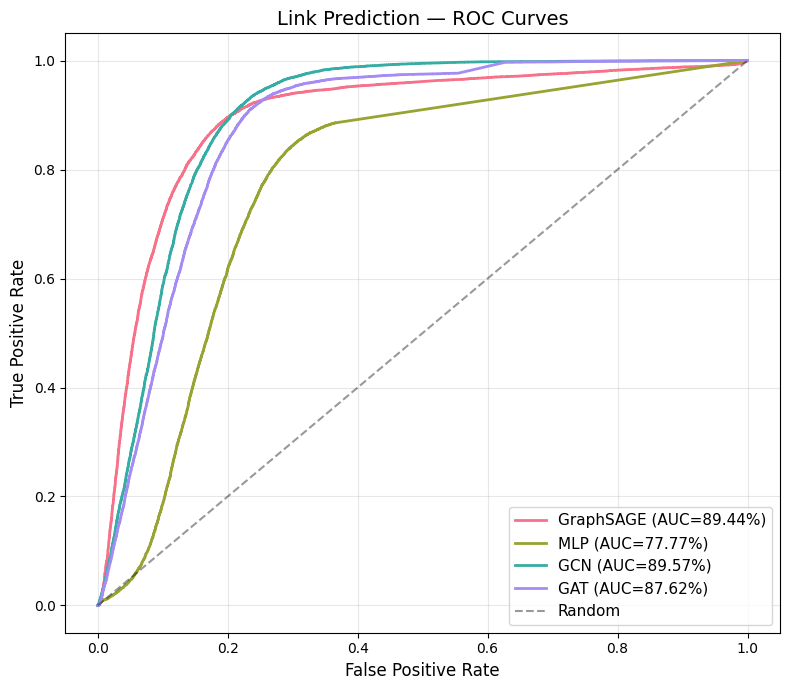


=== LINK PREDICTION COMPARISON ===


,Model,AUC,Accuracy,F1
0,GraphSAGE,89.438314,84.303264,83.102466
1,MLP,77.767798,75.840656,75.692988
2,GCN,89.567080,83.845947,83.274533
3,GAT,87.621392,82.689204,82.195066


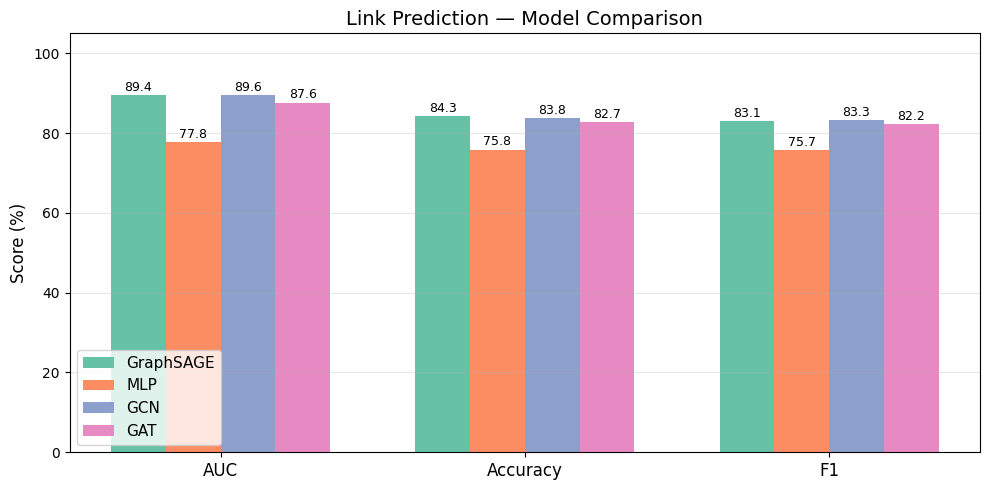

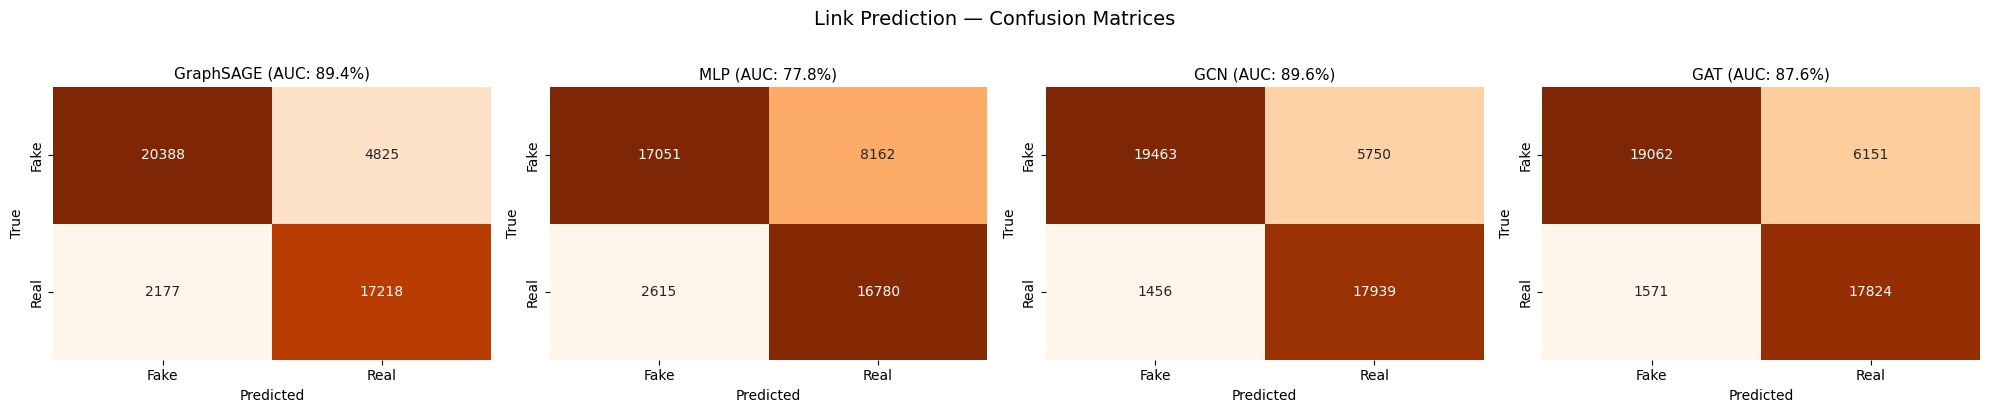

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score, f1_score

from sklearn import metrics as skmetrics

# Collect predictions for all node classification models
nc_models = {}

# GCN
y_pred_gcn_nc = np.argmax(best_model.predict(X_input, batch_size=len(X_input)), axis=1)
nc_models['GCN'] = y_pred_gcn_nc[test_mask]

# GAT
y_pred_gat_nc = best_gat_model.predict(X_full, batch_size=X_full.shape[0]).argmax(axis=1)
nc_models['GAT'] = y_pred_gat_nc[test_mask]

# GraphSAGE
y_pred_sage_nc = best_sage_model.predict(X_full, batch_size=X_full.shape[0]).argmax(axis=1)
nc_models['GraphSAGE'] = y_pred_sage_nc[test_mask]

# MLP
y_pred_mlp_nc = best_mlp_model.predict(X_test_mlp).argmax(axis=1)
nc_models['MLP'] = y_pred_mlp_nc

y_true_nc = y_input[test_mask]

# Build metrics table
nc_rows = []
for name, preds in nc_models.items():
    nc_rows.append({
        'Model': name,
        'Accuracy': skmetrics.accuracy_score(y_true_nc, preds) * 100,
        'Macro F1': skmetrics.f1_score(y_true_nc, preds, average='macro') * 100,
        'Micro F1': skmetrics.f1_score(y_true_nc, preds, average='micro') * 100,
        'Macro Precision': skmetrics.precision_score(y_true_nc, preds, average='macro') * 100,
        'Macro Recall': skmetrics.recall_score(y_true_nc, preds, average='macro') * 100,
    })
nc_df = pd.DataFrame(nc_rows)
print("NODE CLASSIFICATION COMPARISON")
display(nc_df)

# Bar chart
fig, ax = plt.subplots(figsize=(12, 5))
metrics_to_plot = ['Accuracy', 'Macro F1', 'Micro F1', 'Macro Precision', 'Macro Recall']
x = np.arange(len(metrics_to_plot))
width = 0.18
colors = sns.color_palette("Set2", 4)

for i, (name, _) in enumerate(nc_models.items()):
    vals = [nc_df[nc_df['Model'] == name][m].values[0] for m in metrics_to_plot]
    bars = ax.bar(x + i * width, vals, width, label=name, color=colors[i])
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f'{v:.1f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics_to_plot, fontsize=12)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('Node Classification — Model Comparison', fontsize=14)
ax.legend(fontsize=11)
ax.set_ylim(0, 105)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('nc_comparison_bar.png', dpi=300)
plt.show()

# NODE CLASSIFICATION — Confusion Matrices (2x2 grid)
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for ax, (name, preds) in zip(axes, nc_models.items()):
    cm = confusion_matrix(y_true_nc, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=range(16), yticklabels=range(16), cbar=False)
    acc = skmetrics.accuracy_score(y_true_nc, preds) * 100
    ax.set_title(f'{name} (Acc: {acc:.1f}%)', fontsize=12)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
plt.suptitle('Node Classification — Confusion Matrices', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('nc_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

# LINK PREDICTION — ROC Curves Overlay
y_true_lp = y_test_link_augmented.numpy()

lp_scores = {
    'GraphSAGE': link_model.predict(x_test_edges, verbose=0).flatten(),
    'MLP':       mlp_link_model.predict(x_test_edges, verbose=0).flatten(),
    'GCN':       gcn_link_model.predict(x_test_edges, verbose=0).flatten(),
    'GAT':       gat_link_model.predict(x_test_edges, verbose=0).flatten(),
}

fig, ax = plt.subplots(figsize=(8, 7))
colors_lp = sns.color_palette("husl", len(lp_scores))

for (name, scores), color in zip(lp_scores.items(), colors_lp):
    fpr, tpr, _ = roc_curve(y_true_lp, scores)
    auc = roc_auc_score(y_true_lp, scores)
    ax.plot(fpr, tpr, label=f'{name} (AUC={auc*100:.2f}%)', color=color, linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('Link Prediction — ROC Curves', fontsize=14)
ax.legend(fontsize=11, loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('lp_roc_overlay.png', dpi=300)
plt.show()

# LINK PREDICTION — Comparative Bar Chart
lp_thresholds = {
    'GraphSAGE': best_threshold,
    'MLP':       best_thr_mlp,
    'GCN':       best_thr_gcn,
    'GAT':       best_thr_gat,
}

lp_rows = []
for name, scores in lp_scores.items():
    thr = lp_thresholds[name]
    preds_bin = (scores >= thr).astype(int)
    lp_rows.append({
        'Model': name,
        'AUC': roc_auc_score(y_true_lp, scores) * 100,
        'Accuracy': accuracy_score(y_true_lp, preds_bin) * 100,
        'F1': f1_score(y_true_lp, preds_bin) * 100,
    })
lp_df = pd.DataFrame(lp_rows)
print("\n=== LINK PREDICTION COMPARISON ===")
display(lp_df)

fig, ax = plt.subplots(figsize=(10, 5))
lp_metrics = ['AUC', 'Accuracy', 'F1']
x = np.arange(len(lp_metrics))
width = 0.18

for i, name in enumerate(lp_scores.keys()):
    vals = [lp_df[lp_df['Model'] == name][m].values[0] for m in lp_metrics]
    bars = ax.bar(x + i * width, vals, width, label=name, color=colors[i])
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f'{v:.1f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(lp_metrics, fontsize=12)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('Link Prediction — Model Comparison', fontsize=14)
ax.legend(fontsize=11)
ax.set_ylim(0, 105)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('lp_comparison_bar.png', dpi=300)
plt.show()

# LINK PREDICTION — Confusion Matrices
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, scores) in zip(axes, lp_scores.items()):
    thr = lp_thresholds[name]
    preds_bin = (scores >= thr).astype(int)
    cm = confusion_matrix(y_true_lp, preds_bin)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=ax,
                xticklabels=["Fake", "Real"], yticklabels=["Fake", "Real"], cbar=False)
    auc_val = roc_auc_score(y_true_lp, scores) * 100
    ax.set_title(f'{name} (AUC: {auc_val:.1f}%)', fontsize=11)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
plt.suptitle('Link Prediction — Confusion Matrices', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('lp_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import os, pickle, json
import numpy as np

os.makedirs("saved_models", exist_ok=True)

# Save model weights
best_model.save_weights("saved_models/gcn_nc_weights.weights.h5")
best_gat_model.save_weights("saved_models/gat_nc_weights.weights.h5")
best_sage_model.save_weights("saved_models/sage_nc_weights.weights.h5")
best_mlp_model.save_weights("saved_models/mlp_nc_weights.weights.h5")

gcn_link_model.save_weights("saved_models/gcn_lp_weights.weights.h5")
gat_link_model.save_weights("saved_models/gat_lp_weights.weights.h5")
link_model.save_weights("saved_models/sage_lp_weights.weights.h5")
mlp_link_model.save_weights("saved_models/mlp_lp_weights.weights.h5")

# Save encoder configuration for future use
with open("saved_models/encoder_config.pkl", "wb") as f:
    pickle.dump({"type": "sbert", "model_name": "saved_models/sbert_model"}, f)
    
# Save graph data
np.savez(
    "saved_models/graph_data.npz",
    X_full      = X_full,
    y_full      = y_full,
    edge_index  = data.edge_index.numpy(),
    train_mask  = data.train_mask.numpy(),
    val_mask    = data.val_mask.numpy(),
    test_mask   = data.test_mask.numpy(),
    node_names  = np.array(final_asins),
    class_names = np.array(TARGET_CLASSES),
)

# Save ASIN to index mapping for future use
with open("saved_models/asin_to_idx.pkl", "wb") as f:
    pickle.dump({asin: int(idx) for idx, asin in enumerate(final_asins)}, f)

# Save configuration (HP + thresholds), necessary for model reconstruction
lp_config = {
    "thresholds": {
        "GraphSAGE": float(best_threshold),
        "MLP":       float(best_thr_mlp),
        "GCN":       float(best_thr_gcn),
        "GAT":       float(best_thr_gat),
    },
    "num_features": int(X_full.shape[1]),
    "num_classes":  16,
    "num_nodes":    int(X_full.shape[0]),
    "target_classes": TARGET_CLASSES,
    "hp": {
        "gcn_nc": {
            "out_feat": int(best_hp.get("out_feat")),
            "dropout":  float(best_hp.get("dropout")),
        },
        "gat_nc": {
            "num_heads": int(best_hps_gat.get("num_heads")),
            "out_feat":  int(best_hps_gat.get("out_feat")),
            "dropout":   float(best_hps_gat.get("dropout")),
        },
        "sage_nc": {
            "out_feat":   int(best_hps_sage.get("out_feat")),
            "dropout":    float(best_hps_sage.get("dropout")),
            "normalize":  bool(best_hps_sage.get("normalize")),
        },
        "mlp_nc": {
            "units_1":   int(best_hps_mlp.get("units_1")),
            "dropout_1": float(best_hps_mlp.get("dropout_1")),
            "units_2":   int(best_hps_mlp.get("units_2")),
            "dropout_2": float(best_hps_mlp.get("dropout_2")),
        },
        "sage_lp": {
            "out_feat": int(best_hps_link.get("out_feat")),
            "dropout":  float(best_hps_link.get("dropout")),
        },
        "mlp_lp": {
            "hidden_dim": int(best_hps_mlp_link.get("hidden_dim")),
            "dropout":    float(best_hps_mlp_link.get("dropout")),
        },
        "gcn_lp": {
            "out_feat": int(best_hps_gcn_link.get("out_feat")),
            "dropout":  float(best_hps_gcn_link.get("dropout")),
        },
        "gat_lp": {
            "num_heads": int(best_hps_gat_link.get("num_heads")),
            "out_feat":  int(best_hps_gat_link.get("out_feat")),
            "dropout":   float(best_hps_gat_link.get("dropout")),
        },
    }
}

with open("saved_models/lp_config.json", "w") as f:
    json.dump(lp_config, f, indent=2)


✅ Salvat: ['asin_to_idx.pkl', 'encoder_config.pkl', 'gat_lp_weights.weights.h5', 'gat_nc_weights.weights.h5', 'gcn_lp_weights.weights.h5', 'gcn_nc_weights.weights.h5', 'graph_data.npz', 'lp_config.json', 'mlp_lp_weights.weights.h5', 'mlp_nc_weights.weights.h5', 'sage_lp_weights.weights.h5', 'sage_nc_weights.weights.h5']
